# ¿Quién trabaja en la informalidad? Predicción con datos de la ENOE (INEGI)

**Materia:** Analítica Predictiva · **Profesor:** Marco Antonio Cisneros Guevara
**Alumna:** Melany Liliana Santillan Salazar · Centro Universitario de Guadalajara

**Fuente:** INEGI, Encuesta Nacional de Ocupación y Empleo (ENOE), 2.º trimestre de 2026 (tabla `SDEM`).

**Cómo correrlo en Google Colab:** *Entorno de ejecución → Ejecutar todo*. La primera celda descarga los datos directo de INEGI (unos 41 MB), no hay que subir nada.

## Preparación: librerías
Primero importo las librerías que voy a usar:
- `pandas` y `numpy`: para trabajar con tablas y números.
- `matplotlib` y `seaborn`: para hacer las gráficas.
- `scipy.stats`: para pruebas estadísticas sencillas.
- `sklearn` (scikit-learn): para dividir los datos, hacer los modelos y calcular las métricas.

In [1]:
import os, time, json, zipfile, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay)

SEMILLA = 42                      # para que siempre salgan los mismos resultados
np.random.seed(SEMILLA)
os.makedirs("figuras", exist_ok=True)
os.makedirs("resultados", exist_ok=True)

AZUL, NARANJA, GRIS, VERDE, ROJO = "#2563EB", "#F59E0B", "#6B7280", "#10B981", "#DC2626"
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

R = {}   # aquí guardo los resultados importantes para el documento

def guardar(nombre):
    plt.tight_layout()
    plt.savefig("figuras/" + nombre + ".png", dpi=170, bbox_inches="tight")
    plt.show()

## 0. Planteamiento del problema, objetivos e hipótesis

**Problema.** En México más de la mitad de las personas que trabajan están en la **informalidad** (no tienen seguridad social ni prestaciones). Quiero saber qué características se relacionan con trabajar en la informalidad y si se puede **predecir** con datos de la persona.

**Relevancia.** Esto sirve para que el gobierno y las instituciones decidan dónde poner programas de formalización y seguridad social.

**¿Por qué usar análisis de datos?** Porque la ENOE tiene cientos de miles de personas; con tantos datos no se puede ver a simple vista qué factores pesan más, y los modelos de aprendizaje automático ayudan a encontrarlo.

**Objetivo general.** Hacer modelos de clasificación que predigan si una persona ocupada tiene empleo informal (1) o formal (0).

**Objetivos específicos.**
1. Describir de dónde vienen los datos y limpiarlos.
2. Elegir las variables predictoras y revisar que no haya "fuga de información".
3. Comparar 3 modelos (regresión logística, árbol de decisión y bosque aleatorio).
4. Lograr un ROC-AUC de al menos 0.80 en los datos de prueba.
5. Explicar qué variables influyen más y revisar las hipótesis.

**Hipótesis.**
- **H1:** a más escolaridad, menos probabilidad de estar en la informalidad.
- **H2:** vivir en una localidad pequeña (menos de 2,500 habitantes) aumenta la probabilidad de informalidad.
- **H3:** a mayor ingreso, menor probabilidad de informalidad.

**¿Cómo las voy a comprobar?** Con gráficas de porcentajes por grupo, pruebas estadísticas (χ², t de Student, correlación de Spearman) y las razones de momios (odds ratio) de la regresión logística.
Una hipótesis se *respalda* si el resultado va en la dirección esperada y la prueba da p < 0.05; si no, se *rechaza*.

## 1. Procedencia y adquisición de la base de datos

- **Fuente original:** INEGI, ENOE (https://www.inegi.org.mx/programas/enoe/15ymas/).
- **Cómo se obtuvo:** consulté el repositorio oficial de datos abiertos de INEGI y descargué el archivo (no hice encuestas ni *web scraping*).
- **Por qué esta fuente:** es la fuente oficial de empleo e informalidad en México, trae diccionario de datos y es pública.
- **Tabla que uso:** `SDEM` (características sociodemográficas y laborales).

In [2]:
URL = "https://www.inegi.org.mx/contenidos/programas/enoe/15ymas/datosabiertos/2026/conjunto_de_datos_enoe_2026_2t_csv.zip"
ZIP = "datos/enoe_2026_2t.zip"
os.makedirs("datos", exist_ok=True)

# Descargo el zip solo si no existe todavia
if not os.path.exists(ZIP):
    pedido = urllib.request.Request(URL, headers={"User-Agent": "Mozilla/5.0"})
    with urllib.request.urlopen(pedido, timeout=600) as r, open(ZIP, "wb") as f:
        while True:
            pedacito = r.read(1 << 20)
            if not pedacito:
                break
            f.write(pedacito)

# Del zip solo saco la tabla SDEM
with zipfile.ZipFile(ZIP) as z:
    archivos = [a for a in z.namelist() if "sdem" in a]
    z.extractall("datos/enoe", members=archivos)

BASE = "datos/enoe/conjunto_de_datos_sdem_enoe_2026_2t"
datos = pd.read_csv(BASE + "/conjunto_de_datos/conjunto_de_datos_sdem_enoe_2026_2t.csv",
                    encoding="latin1", low_memory=False)

# Catalogo con los nombres de los estados
cat_ent = pd.read_csv(BASE + "/catalogos/cve_ent.csv", encoding="utf-8", dtype=str)   # este catalogo viene en UTF-8 (acentos)
nombres_estados = {}
for i in range(len(cat_ent)):
    nombres_estados[int(cat_ent["CVE_ENT"][i])] = cat_ent["DESCRIP"][i]

# Convierto a numero las columnas que voy a usar (los espacios en blanco quedan como NaN)
columnas = ["eda", "sex", "anios_esc", "niv_ins", "cs_p13_1", "e_con", "t_loc_tri", "cve_ent", "rama",
            "hrsocup", "ingocup", "ing7c", "clase2", "emp_ppal", "fac_tri", "pos_ocu", "emple7c", "seg_soc"]
for c in columnas:
    datos[c] = pd.to_numeric(datos[c], errors="coerce")

R["n_registros"] = int(datos.shape[0])
R["n_variables"] = int(datos.shape[1])
print("Registros:", datos.shape[0], "| Variables:", datos.shape[1])
datos.head()

Registros: 417128 | Variables: 115


,r_def,cve_loc,cve_mun,est,est_d_tri,est_d_men,cve_ageb,t_loc_tri,t_loc_men,cd_a,...,t_tra,emp_ppal,tue_ppal,trans_ppal,mh_fil2,mh_col,sec_ins,tipo,mes_cal,cvegeo
0,0,,7,30,671,671,0,1,1,1,...,0,0,0,0,0,0,0,1,5,9007
1,0,,11,30,671,671,0,1,1,1,...,1,2,2,0,3,2,2,1,6,9011
2,0,,14,40,672,672,0,1,1,1,...,0,0,0,0,0,0,0,1,6,9014
3,0,,2,40,672,672,0,1,1,1,...,1,1,2,0,3,1,2,2,6,9002
4,0,,7,20,670,670,0,1,1,1,...,0,0,0,0,0,0,0,2,6,9007


**¿Por qué los datos son confiables, pertinentes y suficientes?**
- *Confiables:* los publica INEGI con un diseño de muestra oficial y diccionario de datos.
- *Pertinentes:* la variable `emp_ppal` es la medición oficial de informalidad.
- *Suficientes:* hay más de 400 mil registros y 115 variables.

Ahora me quedo solo con la **población de estudio**: personas ocupadas (`clase2 == 1`), de 15 años o más y que INEGI clasificó como formal o informal (`emp_ppal` es 1 o 2).

Población de estudio: 189353
Tasa de informalidad ponderada: 55.1 %  (parecida a la que publica INEGI)
Tasa de informalidad en la muestra: 51.9 %


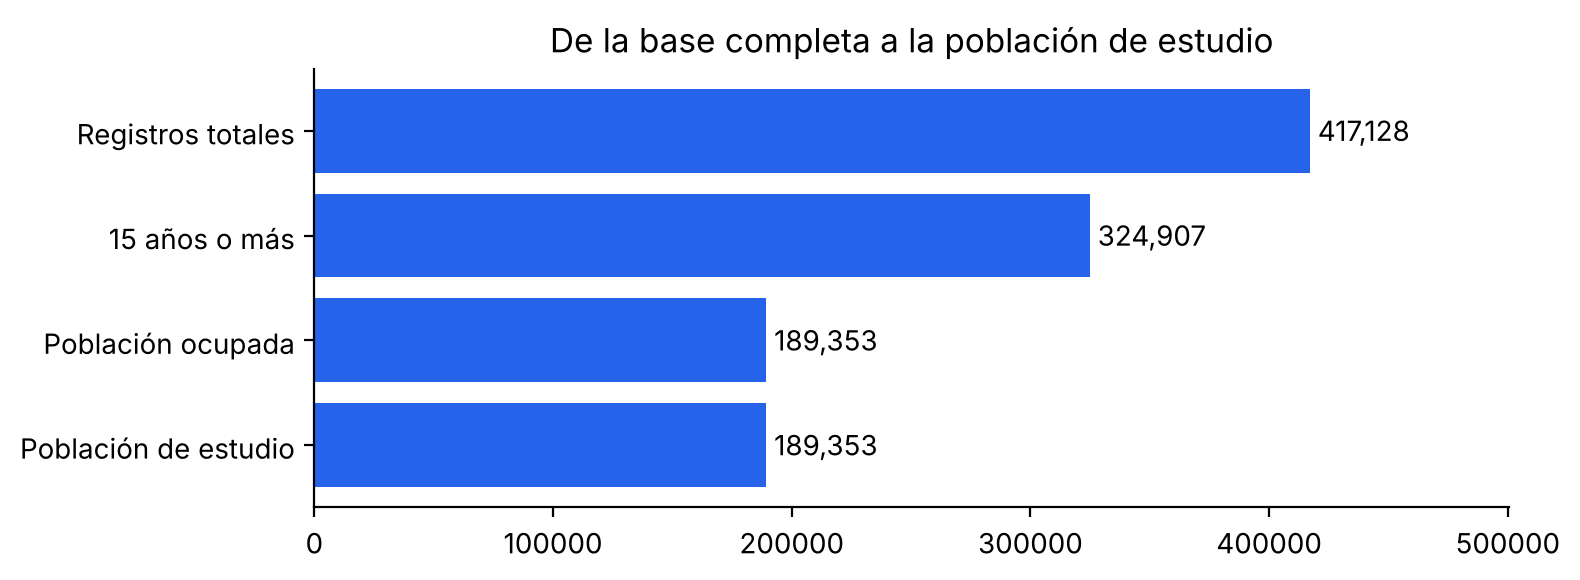

In [3]:
n_total = len(datos)
n_15 = len(datos[datos["eda"] >= 15])
n_ocupados = len(datos[(datos["eda"] >= 15) & (datos["clase2"] == 1)])

d = datos[(datos["eda"] >= 15) & (datos["eda"] <= 98) & (datos["clase2"] == 1) & (datos["emp_ppal"].isin([1, 2]))].copy()
d["y"] = (d["emp_ppal"] == 1).astype(int)       # 1 = informal, 0 = formal

R["embudo"] = {"Registros totales": n_total, "15 años o más": n_15, "Población ocupada": n_ocupados, "Población de estudio": len(d)}
R["n_estudio"] = len(d)

# Tasa de informalidad con factor de expansion (para comparar con INEGI) y sin ponderar
tasa_pond = (d["fac_tri"] * d["y"]).sum() / d["fac_tri"].sum()
R["tasa_pond"] = float(tasa_pond)
R["tasa_muestra"] = float(d["y"].mean())
print("Población de estudio:", len(d))
print("Tasa de informalidad ponderada:", round(tasa_pond * 100, 1), "%  (parecida a la que publica INEGI)")
print("Tasa de informalidad en la muestra:", round(d["y"].mean() * 100, 1), "%")

plt.figure(figsize=(8, 3))
nombres = list(R["embudo"].keys())
valores = list(R["embudo"].values())
plt.barh(nombres[::-1], valores[::-1], color=AZUL)
for i in range(len(valores)):
    plt.text(valores[::-1][i], i, " " + format(valores[::-1][i], ","), va="center")
plt.xlim(0, n_total * 1.2)
plt.title("De la base completa a la población de estudio")
guardar("f01_embudo")

## 2. Limpieza y preprocesamiento de datos

### 2.1 Problemas de calidad que encontré
En la ENOE casi no hay celdas vacías, pero los datos faltantes vienen **escritos como códigos** (por ejemplo 99 = "no especificado"). Si no los quito, el modelo los tomaría como números de verdad. Los busqué en el diccionario de datos.

,Variable,Problema,Registros,% de la población
0,anios_esc,99 = no especificado,622,0.33
1,e_con,9 = no sabe,28,0.01
2,niv_ins,5 = no especificado,500,0.26
3,rama,7 = no especificado,1432,0.76
4,ing7c,7 = ingreso no especificado,19097,10.09
5,hrsocup,0 horas (ausencia temporal),7257,3.83
6,ingocup,0 = sin ingreso,65807,34.75


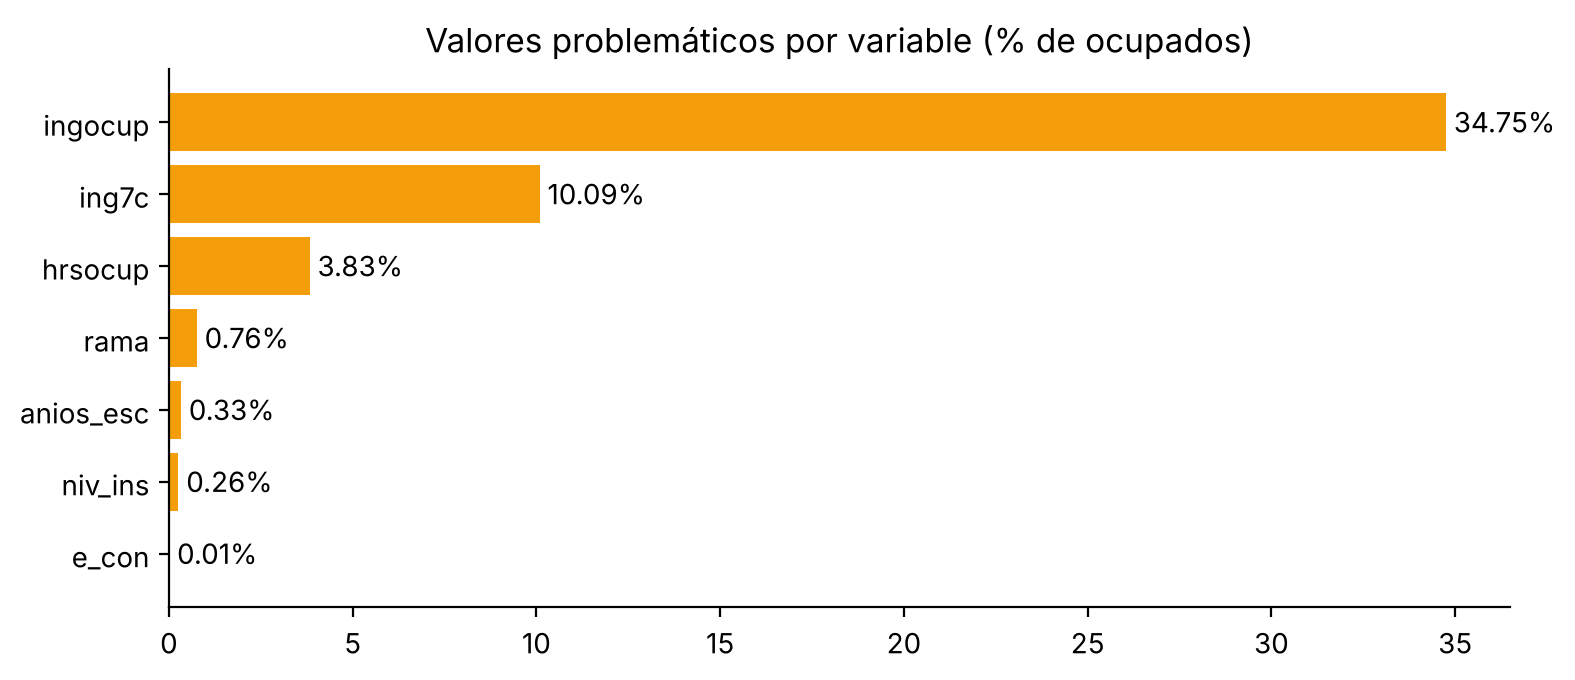

Filas duplicadas: 0


In [4]:
problemas = pd.DataFrame({
    "Variable": ["anios_esc", "e_con", "niv_ins", "rama", "ing7c", "hrsocup", "ingocup"],
    "Problema": ["99 = no especificado", "9 = no sabe", "5 = no especificado", "7 = no especificado",
                 "7 = ingreso no especificado", "0 horas (ausencia temporal)", "0 = sin ingreso"],
    "Registros": [(d["anios_esc"] == 99).sum(), (d["e_con"] == 9).sum(), (d["niv_ins"] == 5).sum(),
                  (d["rama"] == 7).sum(), (d["ing7c"] == 7).sum(), (d["hrsocup"] == 0).sum(), (d["ingocup"] == 0).sum()]})
problemas["% de la población"] = (problemas["Registros"] / len(d) * 100).round(2)
R["auditoria"] = problemas.to_dict("records")
display(problemas)

p = problemas.sort_values("% de la población")
plt.figure(figsize=(8, 3.5))
plt.barh(p["Variable"], p["% de la población"], color=NARANJA)
for i in range(len(p)):
    plt.text(p["% de la población"].values[i], i, " " + str(p["% de la población"].values[i]) + "%", va="center")
plt.title("Valores problemáticos por variable (% de ocupados)")
guardar("f02_calidad")

# Duplicados
duplicados = d.duplicated().sum()
R["duplicados"] = int(duplicados)
print("Filas duplicadas:", duplicados)

### 2.2 ¿Cómo traté los nulos, duplicados e inconsistencias?
- **Duplicados:** busqué filas repetidas con `duplicated()`; si hay, las elimino.
- **Códigos de "no especificado"** (anios_esc = 99, e_con = 9, rama = 7): los cambié por `NaN`.
- **Ingreso:** si `ing7c == 7` el ingreso no se especificó, entonces pongo `NaN`. Si `ing7c == 6` la persona no recibe ingresos (eso sí es información real), así que creo una columna `sin_ingreso` (1 = sí, 0 = no).
- **Horas:** `hrsocup == 0` lo cambié a `NaN`.
- **Rellenar los NaN:** en las variables numéricas uso la **mediana** (calculada solo con los datos de entrenamiento) y en las categóricas pongo la categoría "No especificado".

In [5]:
d = d.drop_duplicates()

# Cambio los codigos por NaN
d["anios_esc"] = d["anios_esc"].where(d["anios_esc"] < 99)
d["hrsocup"] = d["hrsocup"].where(d["hrsocup"] > 0)
d["sin_ingreso"] = (d["ing7c"] == 6).astype(int)
d["ingreso"] = d["ingocup"].where(d["ing7c"] != 7)

# Variables cualitativas: cambio los numeros por texto usando los catalogos de INEGI
d["sexo"] = d["sex"].map({1: "Hombre", 2: "Mujer"})
d["estado_civil"] = d["e_con"].map({1: "Unión libre", 2: "Separado", 3: "Divorciado", 4: "Viudo", 5: "Casado", 6: "Soltero"})
d["localidad"] = d["t_loc_tri"].map({1: "Más de 100 mil", 2: "15 mil a 100 mil", 3: "2.5 mil a 15 mil", 4: "Menos de 2.5 mil"})
d["sector"] = d["rama"].map({6: "Agropecuario", 1: "Construcción", 2: "Manufactura", 3: "Comercio", 4: "Servicios", 5: "Otros"})
d["entidad"] = d["cve_ent"].map(nombres_estados)

# Las categorias vacias las llamo "No especificado"
for c in ["sexo", "estado_civil", "localidad", "sector", "entidad"]:
    d[c] = d[c].fillna("No especificado")

print("Nulos: escolaridad", d["anios_esc"].isna().sum(), "| horas", d["hrsocup"].isna().sum(), "| ingreso", d["ingreso"].isna().sum())

Nulos: escolaridad 622 | horas 7257 | ingreso 19097


### 2.3 Valores atípicos (outliers)
Los **atípicos** son valores muy alejados del resto. Los detecté con la regla del rango intercuartílico (IQR): es atípico lo que pasa de `Q3 + 1.5 × IQR`.
El ingreso tiene unos pocos valores enormes, así que los voy a **limitar al percentil 99** (si alguien gana más que ese valor, le pongo el valor del percentil 99) y luego aplico **logaritmo** para que la distribución sea menos sesgada. No elimino filas, para no perder información. Las horas por semana las muestro con un **histograma**: casi todos trabajan jornadas de 40 a 48 horas (la barra alta) y hay una cola a la derecha con pocas personas que trabajan muchas horas; la línea roja marca el tope que uso (percentil 99).

,limite,n_atipicos,porcentaje
ingreso,30100.0,3383.0,1.99
hrsocup,72.0,4641.0,2.55
eda,84.0,315.0,0.17


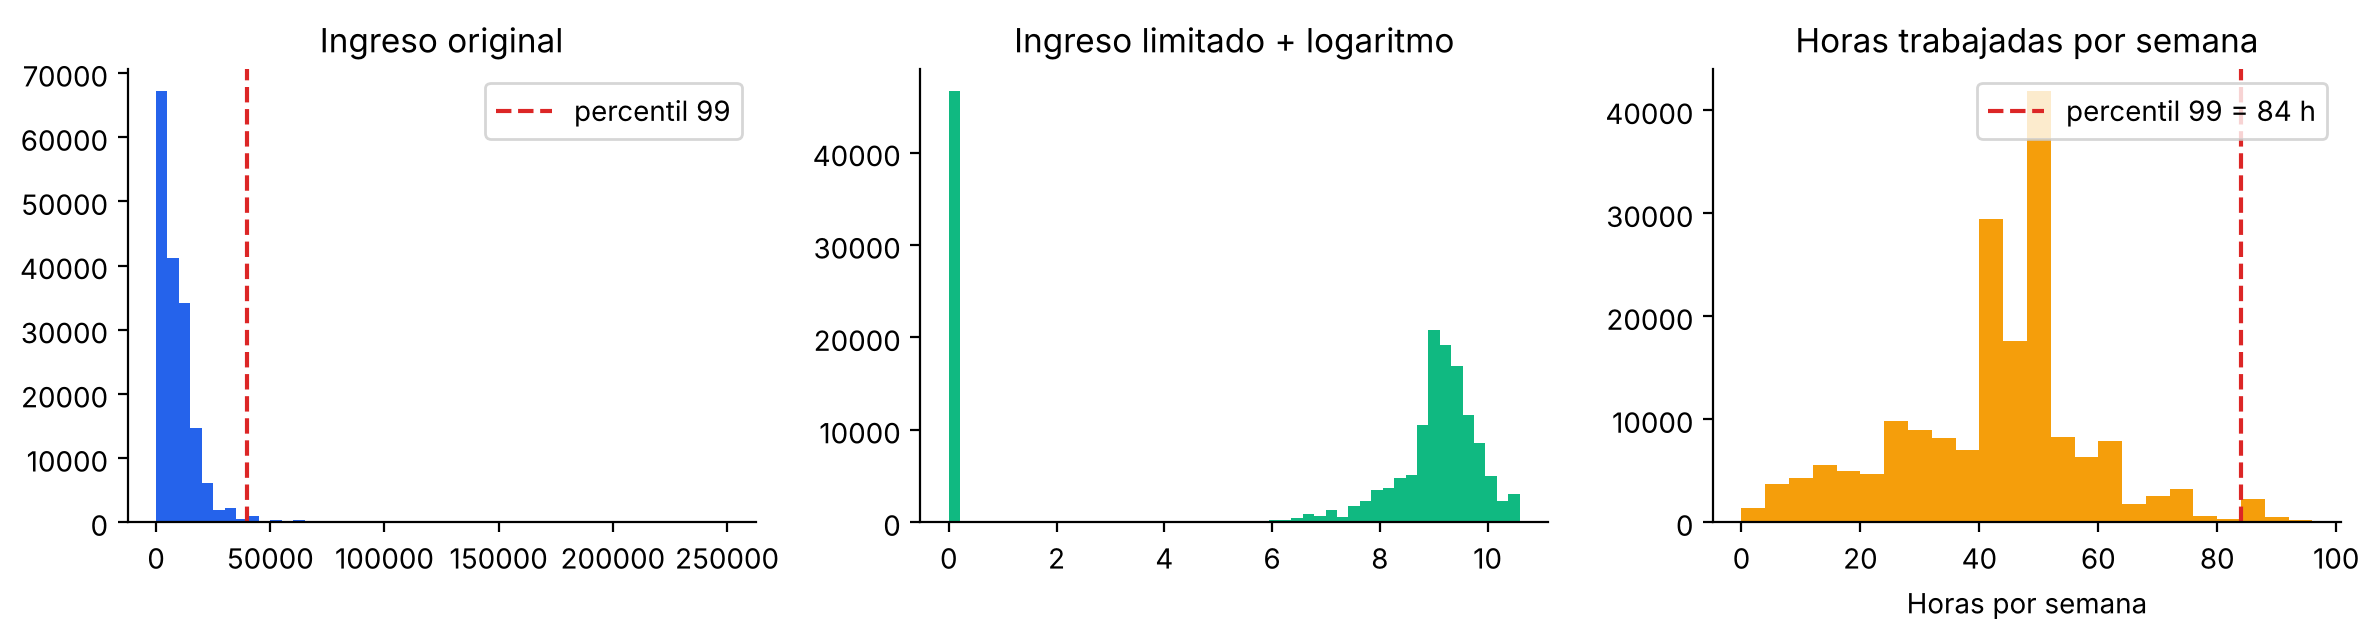

In [6]:
atipicos = {}
for c in ["ingreso", "hrsocup", "eda"]:
    x = d[c].dropna()
    q1 = x.quantile(0.25)
    q3 = x.quantile(0.75)
    limite = q3 + 1.5 * (q3 - q1)
    n = (x > limite).sum()
    atipicos[c] = {"limite": round(float(limite), 1), "n_atipicos": int(n), "porcentaje": round(float(n / len(x) * 100), 2)}
R["atipicos"] = atipicos
display(pd.DataFrame(atipicos).T)

p99 = d["ingreso"].quantile(0.99)
fig, ax = plt.subplots(1, 3, figsize=(12, 3.3))
ax[0].hist(d["ingreso"].dropna(), bins=50, color=AZUL)
ax[0].axvline(p99, color=ROJO, linestyle="--", label="percentil 99")
ax[0].set_title("Ingreso original")
ax[0].legend()
ax[1].hist(np.log1p(d["ingreso"].clip(upper=p99).dropna()), bins=50, color=VERDE)
ax[1].set_title("Ingreso limitado + logaritmo")
tope_h = d["hrsocup"].quantile(0.99)
ax[2].hist(d["hrsocup"].dropna(), bins=range(0, 100, 4), color=NARANJA)
ax[2].axvline(tope_h, color=ROJO, linestyle="--", label="percentil 99 = " + str(int(tope_h)) + " h")
ax[2].set_title("Horas trabajadas por semana")
ax[2].set_xlabel("Horas por semana")
ax[2].legend(loc="upper right")
guardar("f03_outliers")

### 2.4 Cualitativas a cuantitativas, división de datos y estandarización
- **Cualitativas → números:** uso *One-Hot Encoding* con `pd.get_dummies`. Cada categoría se convierte en una columna de 0 y 1 (con `drop_first=True` para quitar una categoría y no repetir información).
- **División:** 80% para entrenar y 20% para probar. Uso `stratify` para que haya la misma proporción de informales en las dos partes.
- **Estandarización:** con `StandardScaler` dejo las variables numéricas con media 0 y desviación 1. Solo la uso en la **regresión logística**, porque esta sí es sensible a la escala. Los árboles no la necesitan.
- Todo lo que se calcula con datos (mediana, percentil 99, media) lo hago **solo con entrenamiento** para no filtrar información de la prueba.

In [7]:
numericas = ["eda", "anios_esc", "hrsocup", "ingreso"]
categoricas = ["sexo", "estado_civil", "localidad", "sector", "entidad"]

# Tabla de predictoras con dummies
X = d[numericas + ["sin_ingreso"] + categoricas].copy()
X = pd.get_dummies(X, columns=categoricas, drop_first=True, dtype=int)
y = d["y"]

# Division entrenamiento / prueba
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEMILLA)
R["n_train"], R["n_test"] = len(X_train), len(X_test)

# Copia de la base de entrenamiento antes de limpiar (para compararla despues)
antes = X_train[numericas].copy()

# Relleno NaN con la mediana del entrenamiento, limito atipicos al p99 y aplico log al ingreso
for c in numericas:
    mediana = X_train[c].median()
    X_train[c] = X_train[c].fillna(mediana)
    X_test[c] = X_test[c].fillna(mediana)

tope_ingreso = X_train["ingreso"].quantile(0.99)
tope_horas = X_train["hrsocup"].quantile(0.99)
for tabla in [X_train, X_test]:
    tabla["ingreso"] = np.log1p(tabla["ingreso"].clip(upper=tope_ingreso))
    tabla["hrsocup"] = tabla["hrsocup"].clip(upper=tope_horas)
R["topes"] = {"ingreso": float(tope_ingreso), "horas": float(tope_horas)}

# Version estandarizada (solo para la regresion logistica)
escalador = StandardScaler()
X_train_esc = X_train.copy()
X_test_esc = X_test.copy()
X_train_esc[numericas] = escalador.fit_transform(X_train[numericas])
X_test_esc[numericas] = escalador.transform(X_test[numericas])

print("Entrenamiento:", X_train.shape, "| Prueba:", X_test.shape)
print("Informales en train:", round(y_train.mean() * 100, 1), "% | en test:", round(y_test.mean() * 100, 1), "%")
print("Nulos que quedan en X_train:", int(X_train.isna().sum().sum()))

Entrenamiento: (151482, 52) | Prueba: (37871, 52)
Informales en train: 51.9 % | en test: 51.9 %
Nulos que quedan en X_train: 0


### 2.5 Diferencias entre la base original y la procesada, y verificación
Para revisar que mis transformaciones **no cambiaron indebidamente** la información, comparo la media, la mediana y la correlación con la variable objetivo **antes y después** de limpiar.

,Variable,Media antes,Media después,Mediana antes,Mediana después,Corr. con y antes,Corr. con y después
0,eda,40.749,40.749,40.000,40.000,0.033,0.033
1,anios_esc,11.082,11.085,12.000,12.000,-0.373,-0.372
2,hrsocup,41.528,41.574,45.000,45.000,-0.227,-0.227
3,ingreso,6.579,6.816,8.954,8.954,-0.027,-0.036


,,Filas,Columnas,Valores nulos
0,Base original (SDEM),417128,115,120147
1,Base procesada (X_train),151482,52,0


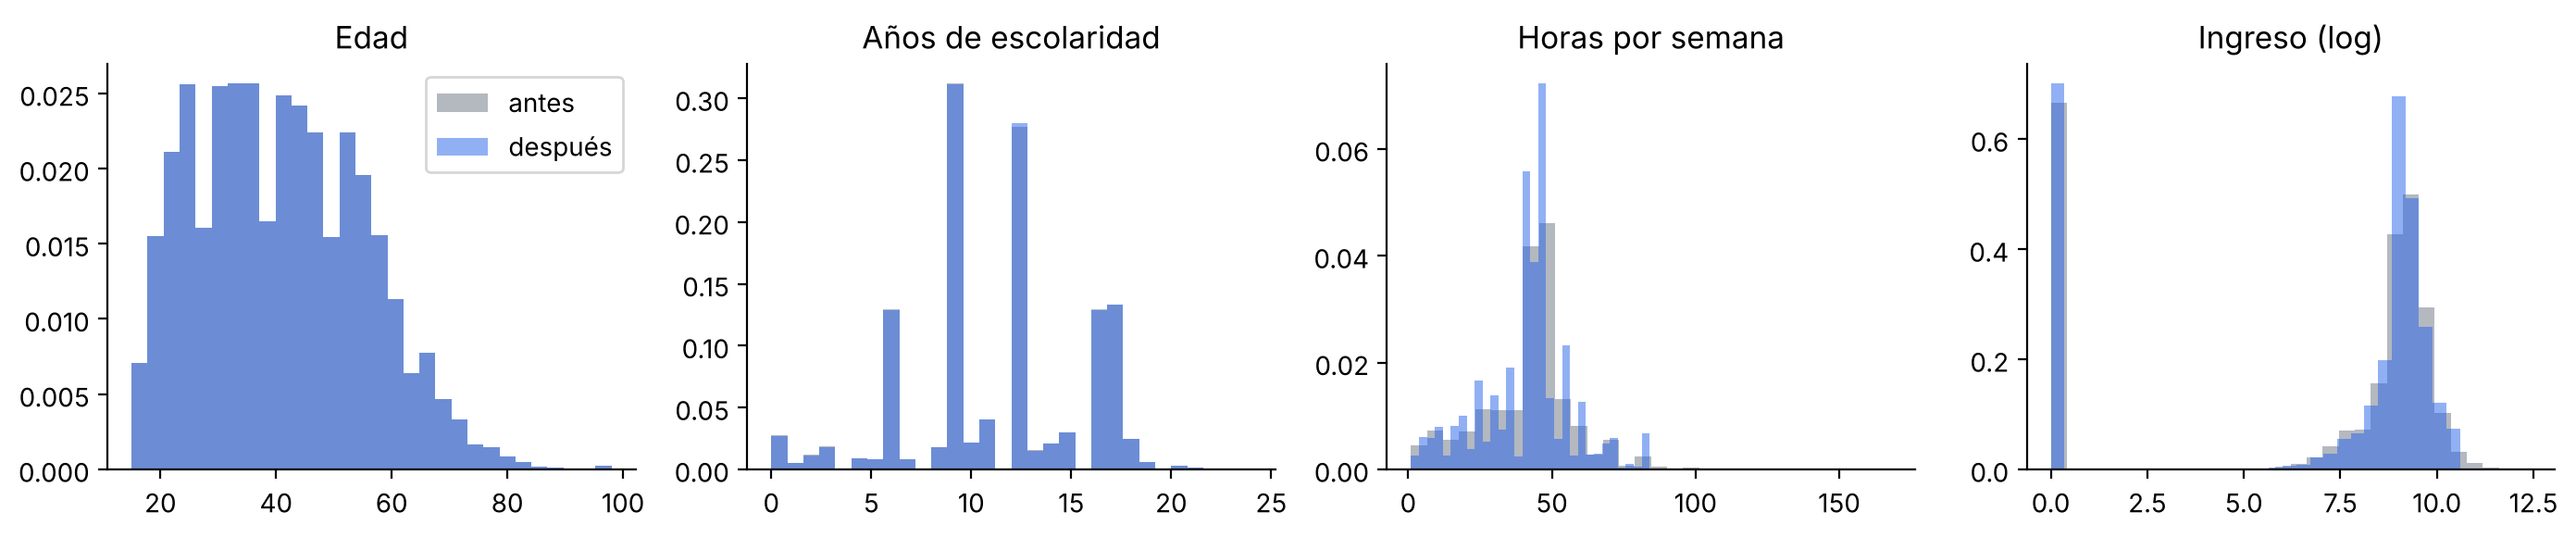

In [8]:
filas = []
for c in numericas:
    a = antes[c].dropna()
    if c == "ingreso":
        a = np.log1p(a)                  # comparo en la misma escala (log)
    b = X_train[c]
    filas.append({"Variable": c,
                  "Media antes": a.mean(), "Media después": b.mean(),
                  "Mediana antes": a.median(), "Mediana después": b.median(),
                  "Corr. con y antes": np.corrcoef(a, y_train.loc[a.index])[0, 1],
                  "Corr. con y después": np.corrcoef(b, y_train)[0, 1]})
comparacion = pd.DataFrame(filas).round(3)
R["verificacion"] = comparacion.to_dict("records")
display(comparacion)

resumen = pd.DataFrame({"": ["Base original (SDEM)", "Base procesada (X_train)"],
                        "Filas": [datos.shape[0], X_train.shape[0]],
                        "Columnas": [datos.shape[1], X_train.shape[1]],
                        "Valores nulos": [int(datos.isna().sum().sum()), int(X_train.isna().sum().sum())]})
R["orig_vs_proc"] = resumen.to_dict("records")
display(resumen)

fig, ax = plt.subplots(1, 4, figsize=(14, 3))
titulos = ["Edad", "Años de escolaridad", "Horas por semana", "Ingreso (log)"]
for i in range(4):
    c = numericas[i]
    a = antes[c].dropna()
    if c == "ingreso":
        a = np.log1p(a)
    ax[i].hist(a, bins=30, alpha=0.5, color=GRIS, density=True, label="antes")
    ax[i].hist(X_train[c], bins=30, alpha=0.5, color=AZUL, density=True, label="después")
    ax[i].set_title(titulos[i])
ax[0].legend()
guardar("f04_antes_despues")

## 3. Identificación y clasificación de variables

**Variables que uso en el modelo** (nombre en mi código, nombre original en la ENOE y qué significa):

| Nombre en mi código | Nombre original ENOE | Qué significa | Tipo | Valores |
|---|---|---|---|---|
| `y` | `emp_ppal` | Variable objetivo: 1 si la persona está en empleo informal, 0 si está en empleo formal | Cualitativa binaria | 1 = informal, 0 = formal |
| `eda` | `eda` | Edad de la persona en años cumplidos | Cuantitativa | 15 a 98 años |
| `anios_esc` | `anios_esc` | Años de escuela aprobados (0 = sin escuela, 12 = bachillerato, 17 o más = posgrado) | Cuantitativa | 0 a 24; 99 = no especificado (lo cambié a NaN) |
| `hrsocup` | `hrsocup` | Horas que trabaja a la semana en su ocupación | Cuantitativa | 0 a 168; 0 = ausencia temporal (lo cambié a NaN) |
| `ingreso` | `ingocup` | Ingreso mensual por su trabajo, en pesos | Cuantitativa | $0 a $250,000 (limitado al percentil 99 y con logaritmo) |
| `sin_ingreso` | `ing7c (la creé)` | Vale 1 si la persona no recibe ingresos por su trabajo (ing7c = 6), 0 si sí recibe | Cuantitativa binaria | 0 o 1 |
| `sexo` | `sex` | Sexo de la persona | Cualitativa nominal | Hombre, Mujer |
| `estado_civil` | `e_con` | Situación conyugal | Cualitativa nominal | Soltero, Casado, Unión libre, Separado, Divorciado, Viudo |
| `localidad` | `t_loc_tri` | Tamaño de la localidad donde vive | Cualitativa ordinal | Menos de 2.5 mil, 2.5 mil a 15 mil, 15 mil a 100 mil, Más de 100 mil habitantes |
| `sector` | `rama` | Sector de actividad económica donde trabaja | Cualitativa nominal | Agropecuario, Construcción, Manufactura, Comercio, Servicios, Otros |
| `entidad` | `cve_ent` | Estado de la República donde vive | Cualitativa nominal | 32 entidades |

**Otras variables que revisé pero NO usé como predictoras:**

| Variable | Qué significa | ¿Por qué no la usé? |
|---|---|---|
| `clase2` | Condición de actividad (1 = población ocupada); la usé para filtrar a las personas que trabajan | Filtro |
| `fac_tri` | Factor de expansión trimestral: cuántas personas de la población representa cada registro. Lo usé solo para calcular la tasa de informalidad ponderada | Comprobación |
| `niv_ins` | Nivel de instrucción (primaria, secundaria, medio superior y superior) | Redundante con anios_esc (corr. 0.92) |
| `cs_p13_1` | Nivel de escolaridad que cursó (ninguno, primaria, secundaria, licenciatura, etc.) | Redundante con anios_esc (corr. 0.98) |
| `ing7c` | Ingreso en grupos de salarios mínimos; 6 = no recibe ingresos y 7 = no especificado | Solo para limpiar el ingreso |
| `seg_soc` | Acceso a servicios médicos como prestación del trabajo | Fuga de información (define la informalidad) |
| `pos_ocu` | Posición en la ocupación (subordinado, empleador, por cuenta propia, sin pago) | Fuga de información |
| `emple7c` | Tamaño de la unidad económica (cuántas personas trabajan en el negocio) | Fuga de información |

### 3.1 ¿Hay relación entre las variables y la variable objetivo?
Primero veo el porcentaje de informalidad por grupos (si cambia mucho entre grupos, hay relación) y después hago pruebas estadísticas.

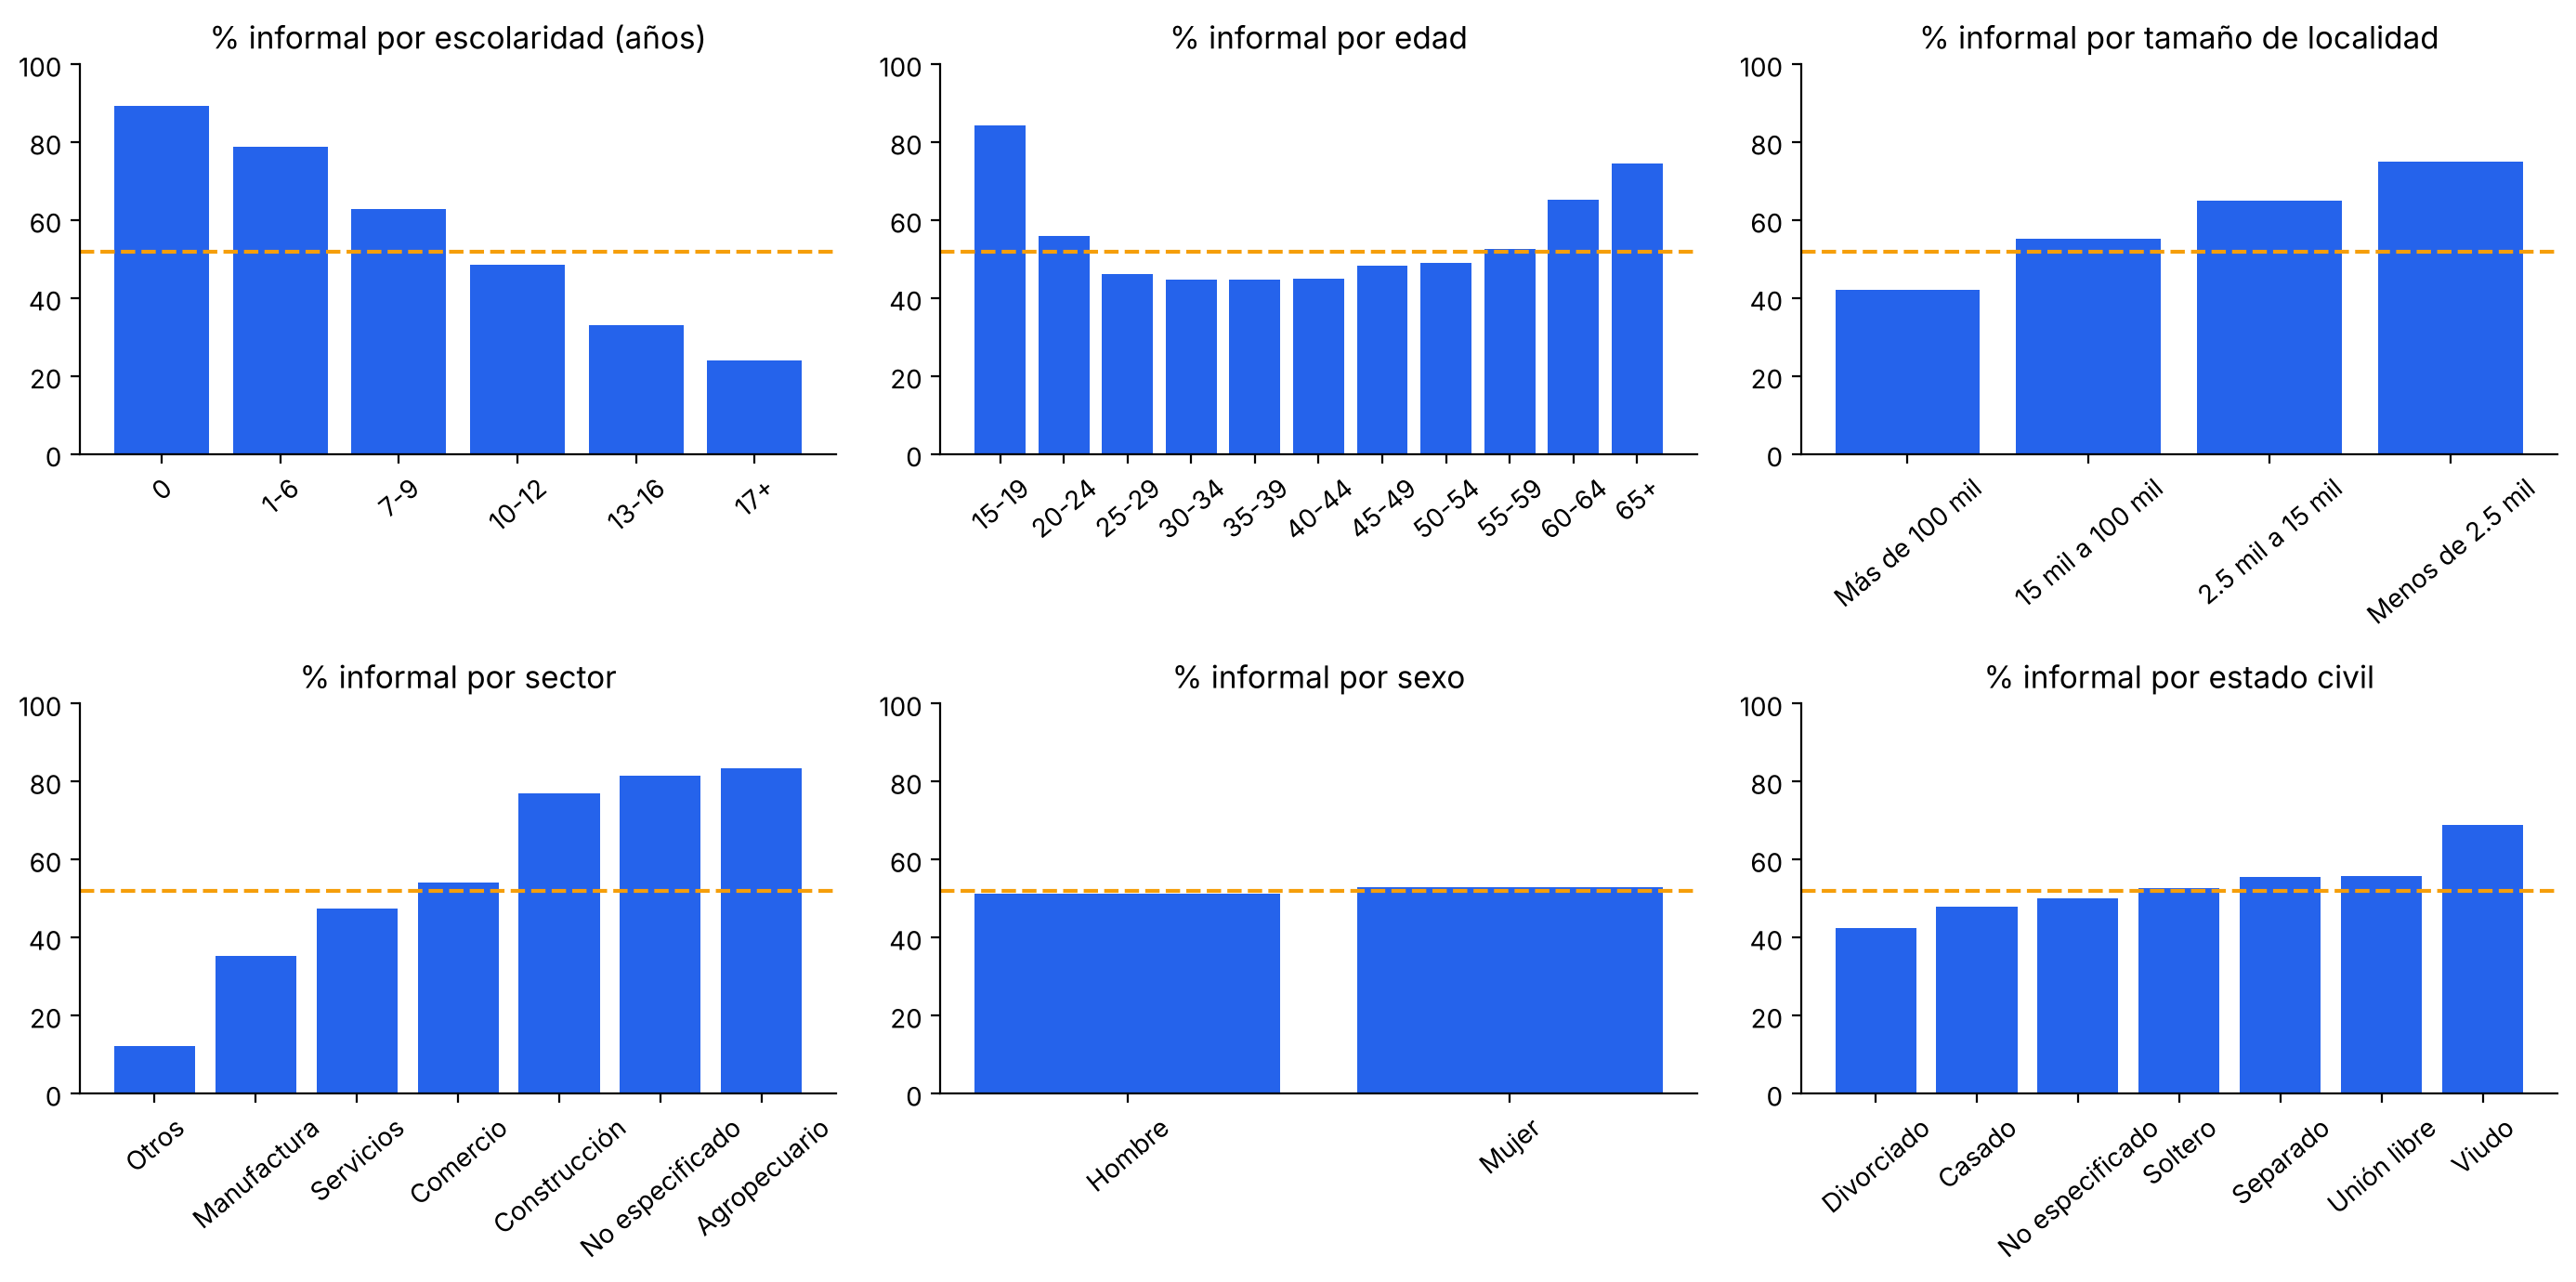

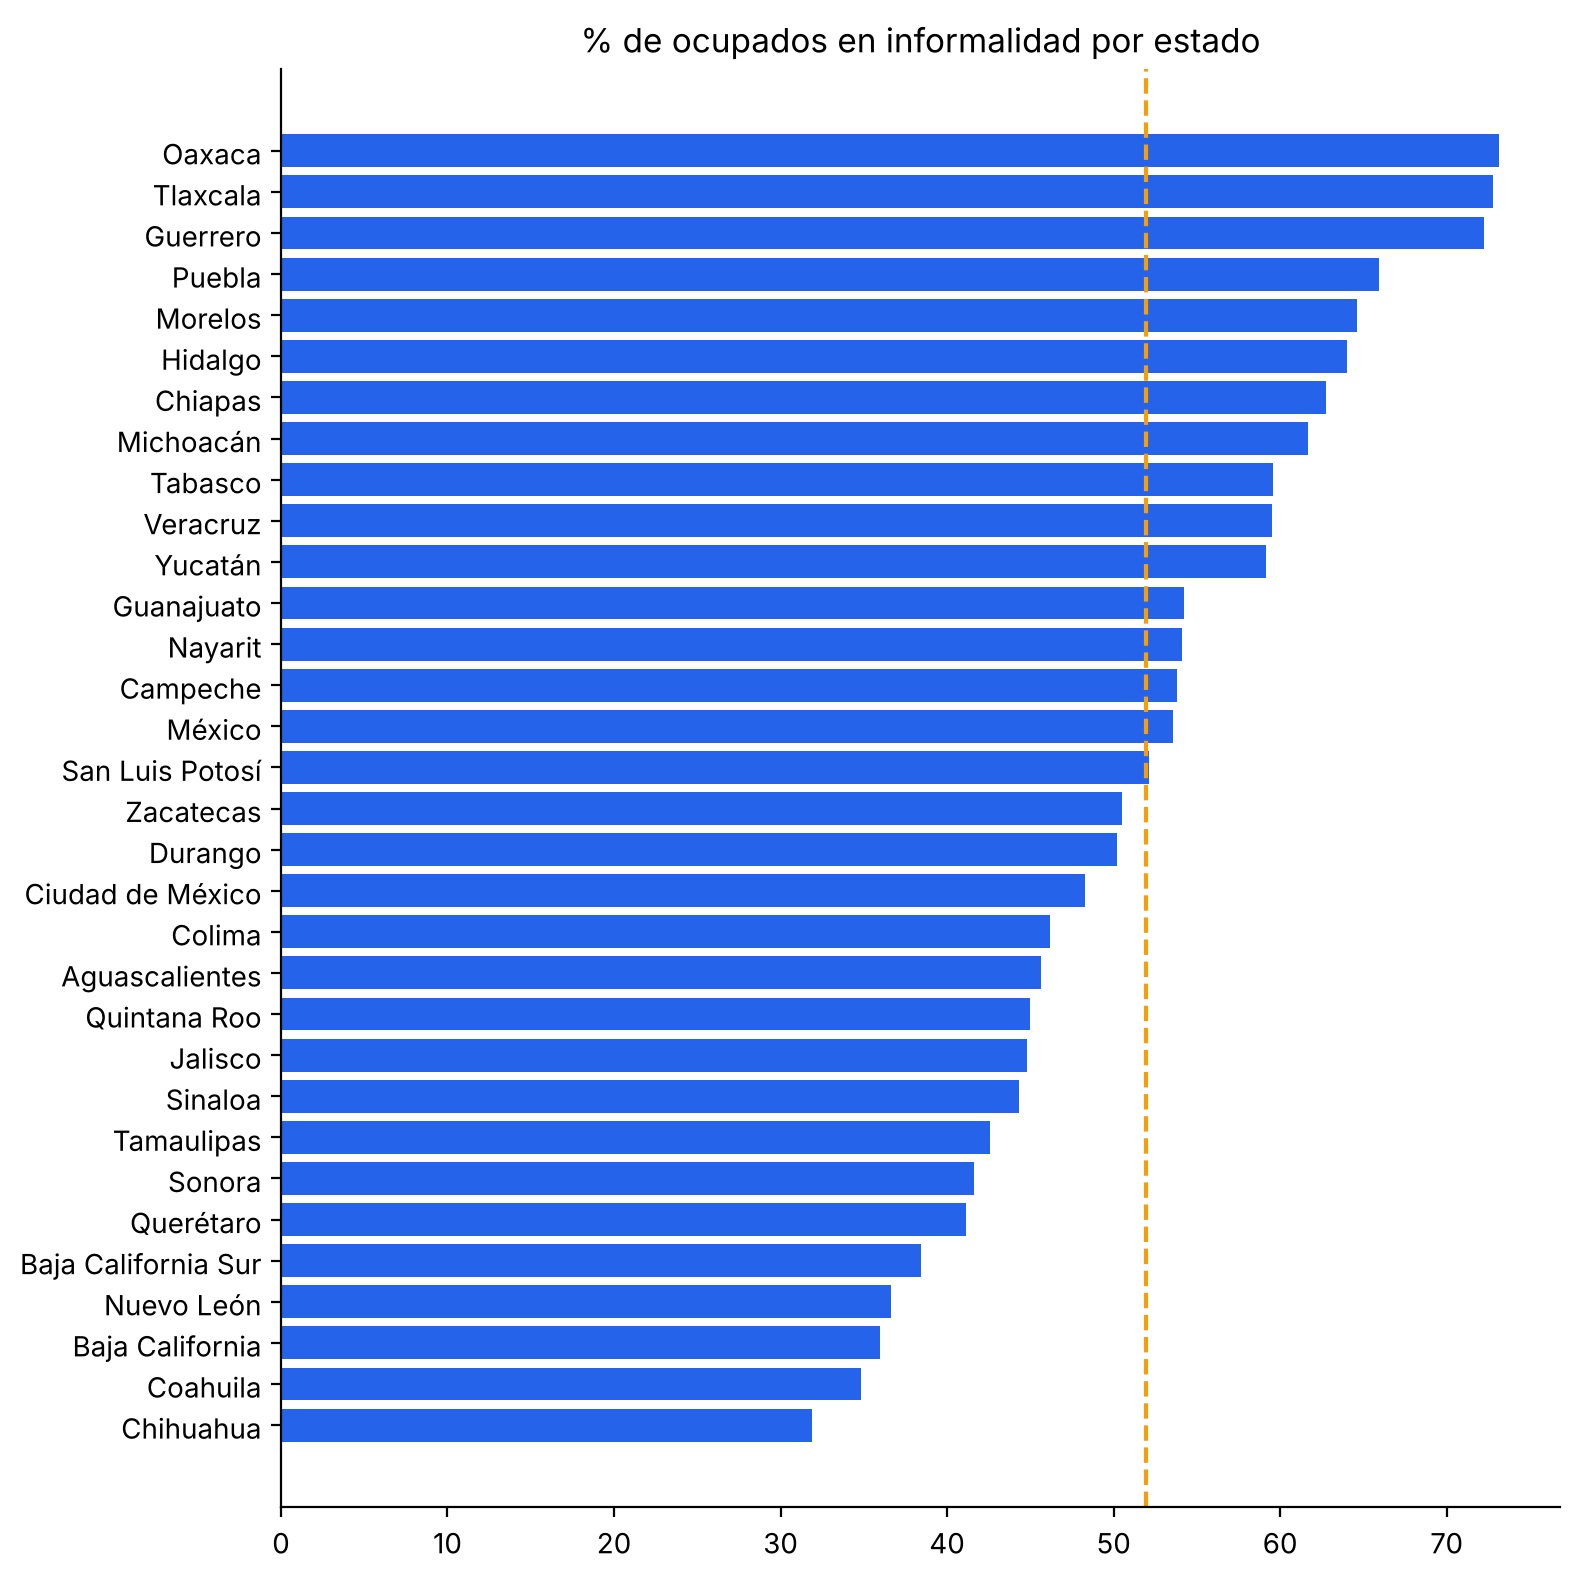

In [9]:
d["grupo_esc"] = pd.cut(d["anios_esc"], [-1, 0, 6, 9, 12, 16, 30], labels=["0", "1-6", "7-9", "10-12", "13-16", "17+"])
d["grupo_edad"] = pd.cut(d["eda"], [14, 19, 24, 29, 34, 39, 44, 49, 54, 59, 64, 98],
                         labels=["15-19", "20-24", "25-29", "30-34", "35-39", "40-44", "45-49", "50-54", "55-59", "60-64", "65+"])

fig, ax = plt.subplots(2, 3, figsize=(14, 7))
variables = ["grupo_esc", "grupo_edad", "localidad", "sector", "sexo", "estado_civil"]
titulos = ["escolaridad (años)", "edad", "tamaño de localidad", "sector", "sexo", "estado civil"]
R["tasas"] = {}
for i in range(6):
    t = d.groupby(variables[i], observed=True)["y"].mean() * 100
    if variables[i] in ["sector", "estado_civil", "localidad"]:
        t = t.sort_values()
    ax.ravel()[i].bar(t.index.astype(str), t.values, color=AZUL)
    ax.ravel()[i].axhline(d["y"].mean() * 100, color=NARANJA, linestyle="--")
    ax.ravel()[i].set_title("% informal por " + titulos[i])
    ax.ravel()[i].tick_params(axis="x", rotation=40)
    ax.ravel()[i].set_ylim(0, 100)
    R["tasas"][variables[i]] = t.round(1).to_dict()
guardar("f05_tasas_grupo")

por_estado = (d.groupby("entidad")["y"].mean() * 100).sort_values()
plt.figure(figsize=(8, 8))
plt.barh(por_estado.index, por_estado.values, color=AZUL)
plt.axvline(d["y"].mean() * 100, color=NARANJA, linestyle="--")
plt.title("% de ocupados en informalidad por estado")
guardar("f06_entidades")
R["estados_altos"] = por_estado.tail(3).round(1).to_dict()
R["estados_bajos"] = por_estado.head(3).round(1).to_dict()

,Variable,Prueba,Fuerza,p-value
7,anios_esc,t de Student,0.8064,0.0
9,ingreso,t de Student,0.4733,0.0
8,hrsocup,t de Student,0.4730,0.0
3,sector,Chi cuadrada,0.2861,0.0
2,localidad,Chi cuadrada,0.2556,0.0
4,entidad,Chi cuadrada,0.2290,0.0
5,sin_ingreso,Chi cuadrada,0.1904,0.0
1,estado_civil,Chi cuadrada,0.0918,0.0
6,eda,t de Student,0.0680,0.0
0,sexo,Chi cuadrada,0.0166,0.0


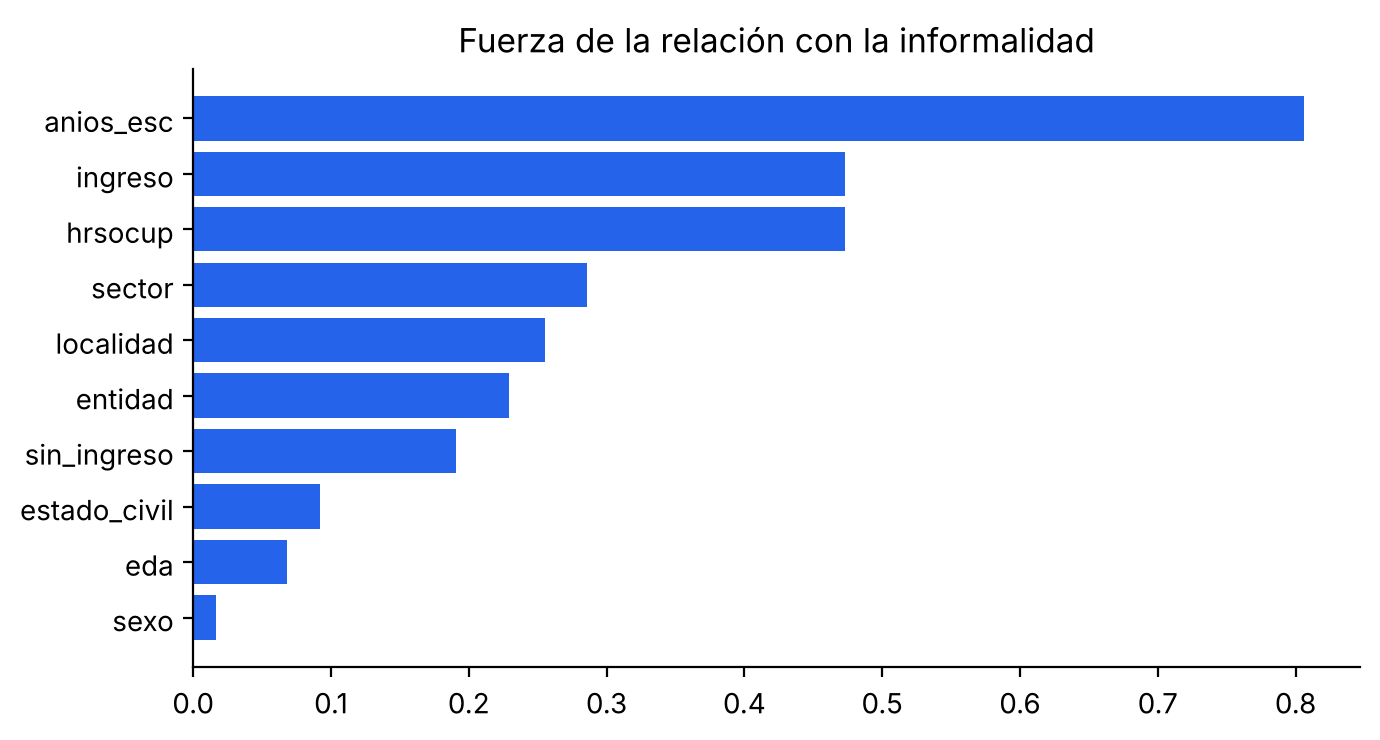

In [10]:
# Pruebas estadisticas sencillas
pruebas = []

# Chi cuadrada para variables cualitativas (relacion con y)
for c in categoricas + ["sin_ingreso"]:
    tabla = pd.crosstab(d[c], d["y"])
    chi2, p, gl, esperados = stats.chi2_contingency(tabla)
    v_cramer = np.sqrt(chi2 / (tabla.values.sum() * (min(tabla.shape) - 1)))     # fuerza de la relacion (0 a 1)
    pruebas.append({"Variable": c, "Prueba": "Chi cuadrada", "Fuerza": v_cramer, "p-value": p})

# Para numericas comparo informales contra formales (t de Student) y calculo el tamaño del efecto
for c in numericas:
    inf = d[d["y"] == 1][c].dropna()
    form = d[d["y"] == 0][c].dropna()
    t, p = stats.ttest_ind(inf, form, equal_var=False)
    efecto = abs(inf.mean() - form.mean()) / np.sqrt((inf.var() + form.var()) / 2)
    pruebas.append({"Variable": c, "Prueba": "t de Student", "Fuerza": efecto, "p-value": p})

pruebas = pd.DataFrame(pruebas).sort_values("Fuerza", ascending=False)
R["pruebas"] = pruebas.to_dict("records")
display(pruebas.round(4))

plt.figure(figsize=(7, 3.8))
plt.barh(pruebas["Variable"][::-1], pruebas["Fuerza"][::-1], color=AZUL)
plt.title("Fuerza de la relación con la informalidad")
guardar("f07_relacion")

### 3.2 Variables redundantes
`niv_ins` y `cs_p13_1` miden casi lo mismo que `anios_esc` (la escolaridad). Si las incluyera todas, el modelo tendría información repetida. Lo reviso con la correlación de Spearman.

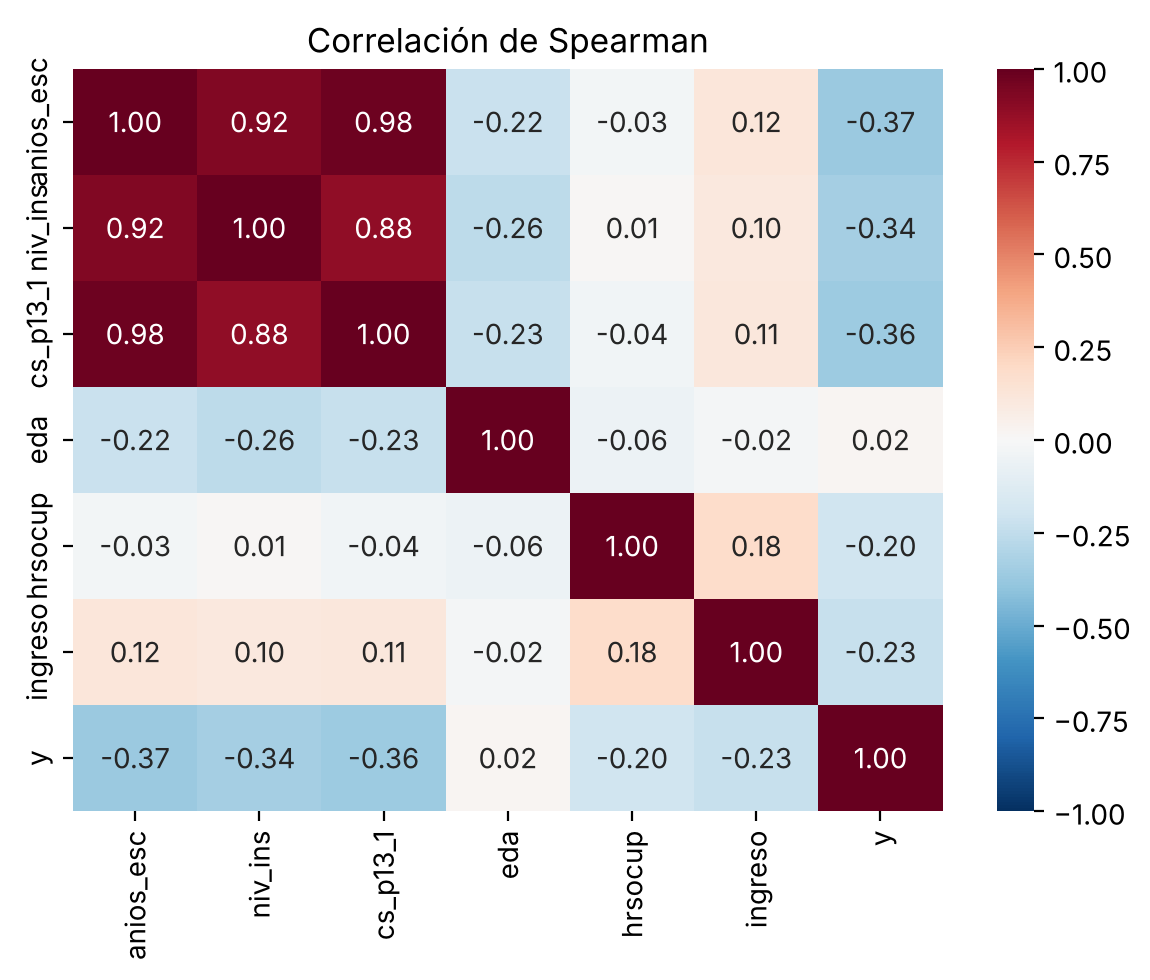

Correlación de anios_esc con niv_ins: 0.92 y con cs_p13_1: 0.98


In [11]:
cols = d[["anios_esc", "niv_ins", "cs_p13_1", "eda", "hrsocup", "ingreso", "y"]].replace(99, np.nan)
corr = cols.corr(method="spearman")
R["corr_redundantes"] = {"niv_ins": float(corr.loc["anios_esc", "niv_ins"]), "cs_p13_1": float(corr.loc["anios_esc", "cs_p13_1"])}

plt.figure(figsize=(6, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1)
plt.title("Correlación de Spearman")
guardar("f08_correlacion")
print("Correlación de anios_esc con niv_ins:", round(R["corr_redundantes"]["niv_ins"], 2), "y con cs_p13_1:", round(R["corr_redundantes"]["cs_p13_1"], 2))

### 3.3 Fuga de información (data leakage)
INEGI define la informalidad usando variables como el **acceso a seguridad social** (`seg_soc`), la **posición en la ocupación** (`pos_ocu`) y el **tamaño de la unidad económica** (`emple7c`). Si las pongo como predictoras, el modelo "ya conoce la respuesta". Lo probé con un árbol de decisión con y sin esas variables.

,ROC-AUC en prueba
Sin variables de fuga (mi modelo),0.8444
+ seg_soc (seguridad social),0.9765
+ pos_ocu (posición en la ocupación),0.8716
+ emple7c (tamaño de la unidad),0.9145
+ las tres juntas,0.9932


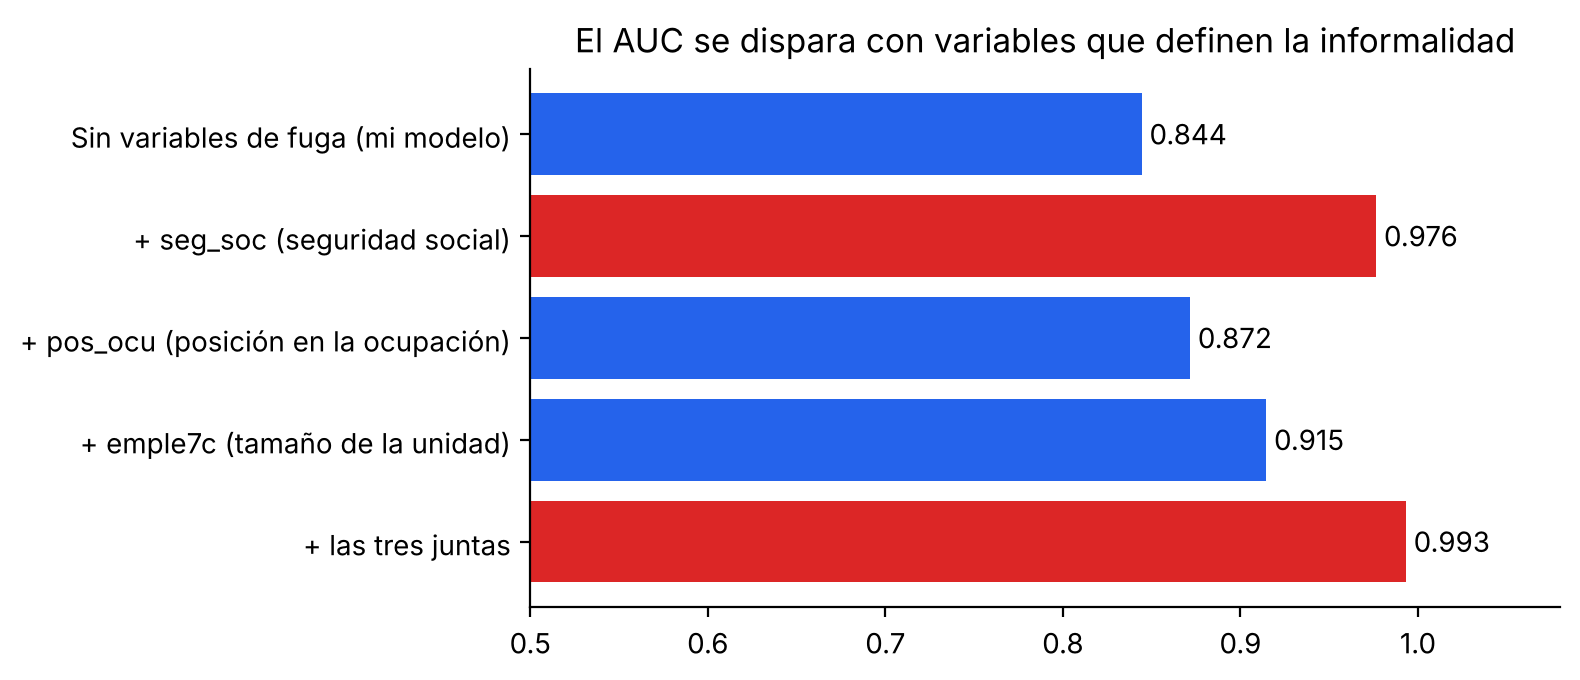

Por eso NO uso seg_soc, pos_ocu ni emple7c en el modelo final.


In [12]:
def auc_arbol(columnas_extra):
    entrena = X_train.copy()
    prueba = X_test.copy()
    for c in columnas_extra:
        entrena[c] = d.loc[X_train.index, c].fillna(0)
        prueba[c] = d.loc[X_test.index, c].fillna(0)
    arbol = DecisionTreeClassifier(max_depth=8, random_state=SEMILLA)
    arbol.fit(entrena, y_train)
    return roc_auc_score(y_test, arbol.predict_proba(prueba)[:, 1])

fuga = {"Sin variables de fuga (mi modelo)": auc_arbol([]),
        "+ seg_soc (seguridad social)": auc_arbol(["seg_soc"]),
        "+ pos_ocu (posición en la ocupación)": auc_arbol(["pos_ocu"]),
        "+ emple7c (tamaño de la unidad)": auc_arbol(["emple7c"]),
        "+ las tres juntas": auc_arbol(["seg_soc", "pos_ocu", "emple7c"])}
R["fuga"] = fuga
display(pd.Series(fuga).round(4).to_frame("ROC-AUC en prueba"))

nom = list(fuga.keys())
val = list(fuga.values())
plt.figure(figsize=(8, 3.5))
plt.barh(nom[::-1], val[::-1], color=[ROJO if v > 0.95 else AZUL for v in val[::-1]])
for i in range(len(val)):
    plt.text(val[::-1][i], i, " " + str(round(val[::-1][i], 3)), va="center")
plt.xlim(0.5, 1.08)
plt.title("El AUC se dispara con variables que definen la informalidad")
guardar("f09_fuga")
print("Por eso NO uso seg_soc, pos_ocu ni emple7c en el modelo final.")

## 4. Modelos de aprendizaje automático

**Tipo de problema:** *clasificación* (predecir una clase: informal o formal). No es regresión ni agrupamiento.

**Modelos que usé y por qué:**
- **Regresión logística:** es el modelo base, sencillo y se puede interpretar.
- **Árbol de decisión:** se entiende fácil porque son reglas del tipo "si... entonces...".
- **Random Forest (bosque aleatorio):** junta muchos árboles y suele dar mejores resultados y menos sobreajuste.
- **Modelo base (Dummy):** siempre predice la clase más común. Sirve para comprobar que mis modelos sí aprenden algo.

**División de datos:** 80% entrenamiento / 20% prueba. Para buscar los mejores parámetros uso `GridSearchCV` con **validación cruzada de 5 pliegues** en una muestra de 30,000 filas del entrenamiento (para que no tarde tanto). Luego entreno con los mejores parámetros usando todo el entrenamiento. La prueba solo se usa al final.

**Métricas:** accuracy (aciertos totales), precision, recall, F1 y ROC-AUC.

Informal: 51.9 % | Formal: 48.1 %  -> las clases están casi balanceadas


,Modelo,precision,recall,F1
0,Sin class_weight,0.7678,0.7326,0.7498
1,Con class_weight='balanced',0.7796,0.7128,0.7447


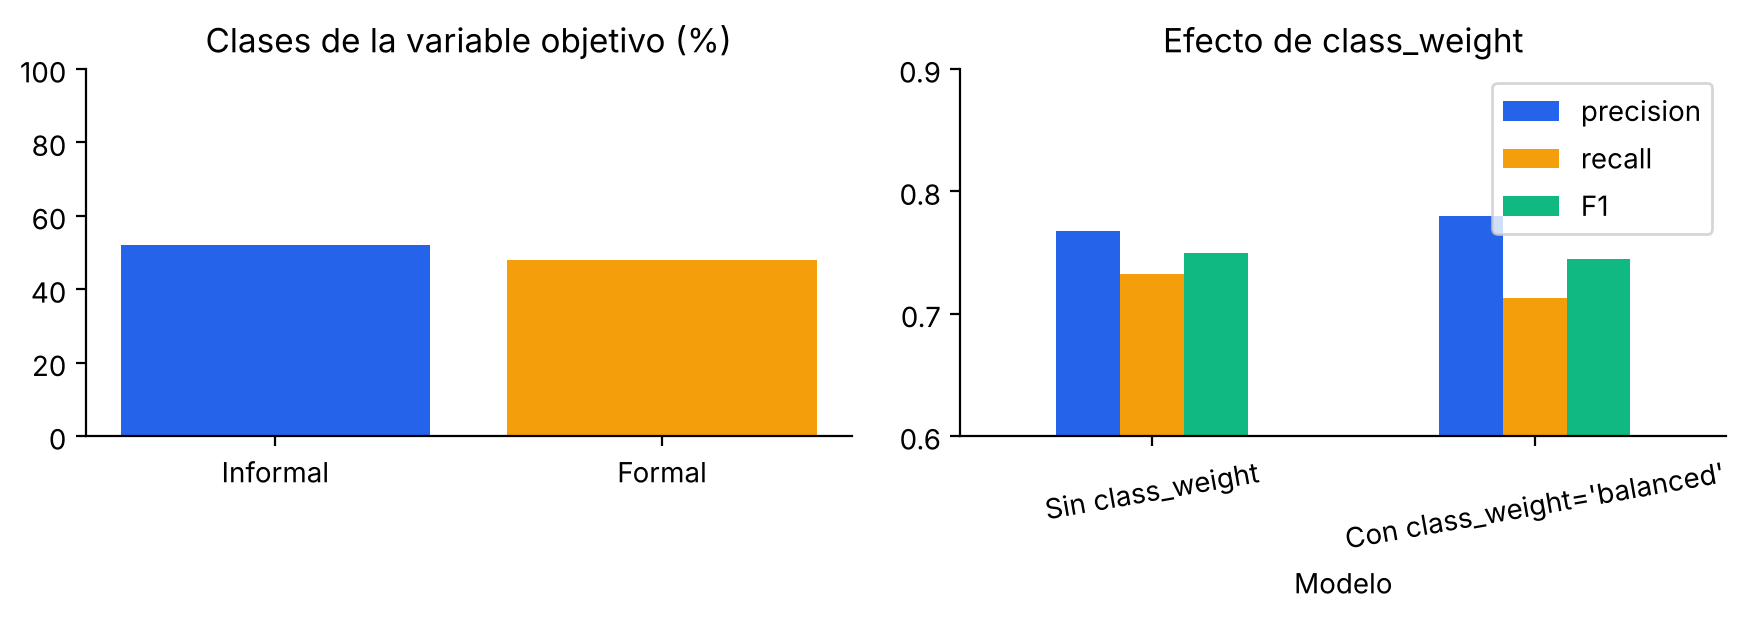

In [13]:
# Balance de clases
balance = y_train.value_counts(normalize=True) * 100
R["balance"] = {"Informal": float(balance[1]), "Formal": float(balance[0])}
print("Informal:", round(balance[1], 1), "% | Formal:", round(balance[0], 1), "%  -> las clases están casi balanceadas")

# Veo si class_weight='balanced' cambia algo
sin_peso = LogisticRegression(max_iter=1000).fit(X_train_esc, y_train)
con_peso = LogisticRegression(max_iter=1000, class_weight="balanced").fit(X_train_esc, y_train)
filas = []
for nombre, m in [("Sin class_weight", sin_peso), ("Con class_weight='balanced'", con_peso)]:
    pred = m.predict(X_test_esc)
    filas.append({"Modelo": nombre, "precision": precision_score(y_test, pred), "recall": recall_score(y_test, pred), "F1": f1_score(y_test, pred)})
pesos = pd.DataFrame(filas).round(4)
R["class_weight"] = pesos.to_dict("records")
display(pesos)

fig, ax = plt.subplots(1, 2, figsize=(9, 3.2))
ax[0].bar(["Informal", "Formal"], [balance[1], balance[0]], color=[AZUL, NARANJA])
ax[0].set_title("Clases de la variable objetivo (%)")
ax[0].set_ylim(0, 100)
pesos.set_index("Modelo")[["precision", "recall", "F1"]].plot.bar(ax=ax[1], color=[AZUL, NARANJA, VERDE], rot=10)
ax[1].set_ylim(0.6, 0.9)
ax[1].set_title("Efecto de class_weight")
guardar("f10_balance")

In [14]:
# Muestra de 30,000 filas para buscar parametros
muestra = X_train.sample(30000, random_state=SEMILLA).index

# Parametros que voy a probar en cada modelo
parametros = {
    "Regresión logística": {"C": [0.01, 0.1, 1, 10]},
    "Árbol de decisión": {"max_depth": [3, 5, 8, 12], "min_samples_leaf": [20, 50, 100]},
    "Random Forest": {"n_estimators": [100, 200], "max_depth": [10, 16], "min_samples_leaf": [5, 20]},
}
modelos_base = {
    "Regresión logística": LogisticRegression(max_iter=1000),
    "Árbol de decisión": DecisionTreeClassifier(random_state=SEMILLA),
    "Random Forest": RandomForestClassifier(random_state=SEMILLA, n_jobs=-1),
}

resultados = {}
mejores = {}
probabilidades = {}

# Modelo base (Dummy)
dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
resultados["Modelo base"] = {"accuracy": accuracy_score(y_test, dummy.predict(X_test)),
                             "precision": 0.0, "recall": 0.0, "F1": 0.0, "ROC-AUC": 0.5,
                             "AUC entrenamiento": 0.5, "AUC validación": 0.5, "t_busqueda": 0.0, "t_entrenar": 0.0, "t_predecir": 0.0}

for nombre in modelos_base:
    # La regresion logistica usa datos estandarizados; los arboles no
    if nombre == "Regresión logística":
        Xtr, Xte = X_train_esc, X_test_esc
    else:
        Xtr, Xte = X_train, X_test

    # 1) Busco los mejores parametros con validacion cruzada (5 pliegues)
    t0 = time.time()
    busqueda = GridSearchCV(modelos_base[nombre], parametros[nombre], cv=5, scoring="roc_auc")
    busqueda.fit(Xtr.loc[muestra], y_train.loc[muestra])
    t_busqueda = time.time() - t0

    # 2) Entreno con todo el entrenamiento usando los mejores parametros
    modelo = modelos_base[nombre].set_params(**busqueda.best_params_)
    t0 = time.time()
    modelo.fit(Xtr, y_train)
    t_entrenar = time.time() - t0

    # 3) Evaluo en prueba
    t0 = time.time()
    prob = modelo.predict_proba(Xte)[:, 1]
    t_predecir = (time.time() - t0) * 10000 / len(Xte)       # segundos por cada 10 mil filas
    pred = (prob >= 0.5).astype(int)

    resultados[nombre] = {"accuracy": accuracy_score(y_test, pred), "precision": precision_score(y_test, pred),
                          "recall": recall_score(y_test, pred), "F1": f1_score(y_test, pred),
                          "ROC-AUC": roc_auc_score(y_test, prob),
                          "AUC entrenamiento": roc_auc_score(y_train, modelo.predict_proba(Xtr)[:, 1]),
                          "AUC validación": busqueda.best_score_,
                          "t_busqueda": t_busqueda, "t_entrenar": t_entrenar, "t_predecir": t_predecir}
    mejores[nombre] = modelo
    probabilidades[nombre] = prob
    R.setdefault("mejores_parametros", {})[nombre] = {k: str(v) for k, v in busqueda.best_params_.items()}
    print(nombre, "| mejores parámetros:", busqueda.best_params_, "| AUC prueba:", round(resultados[nombre]["ROC-AUC"], 4))

tabla = pd.DataFrame(resultados).T
tabla["Diferencia train-test"] = tabla["AUC entrenamiento"] - tabla["ROC-AUC"]
R["modelos"] = tabla.round(5).to_dict("index")
display(tabla[["accuracy", "precision", "recall", "F1", "ROC-AUC", "AUC validación", "AUC entrenamiento", "Diferencia train-test"]].round(4))

Regresión logística | mejores parámetros: {'C': 10} | AUC prueba: 0.8217


Árbol de decisión | mejores parámetros: {'max_depth': 12, 'min_samples_leaf': 50} | AUC prueba: 0.8611


Random Forest | mejores parámetros: {'max_depth': 16, 'min_samples_leaf': 5, 'n_estimators': 200} | AUC prueba: 0.8745


,accuracy,precision,recall,F1,ROC-AUC,AUC validación,AUC entrenamiento,Diferencia train-test
Modelo base,0.5193,0.0000,0.0000,0.0000,0.5000,0.5000,0.5000,0.0000
Regresión logística,0.7463,0.7682,0.7326,0.7500,0.8217,0.8207,0.8207,-0.0010
Árbol de decisión,0.7810,0.8206,0.7400,0.7782,0.8611,0.8418,0.8724,0.0114
Random Forest,0.7894,0.8237,0.7564,0.7886,0.8745,0.8690,0.8902,0.0157


**¿Cómo elegí el mejor modelo?** Lo elegí con el **AUC de validación cruzada** (no con la prueba, para no "hacer trampa" mirando los datos de prueba). Después reviso cómo le fue en la prueba.

Mejor modelo: Random Forest


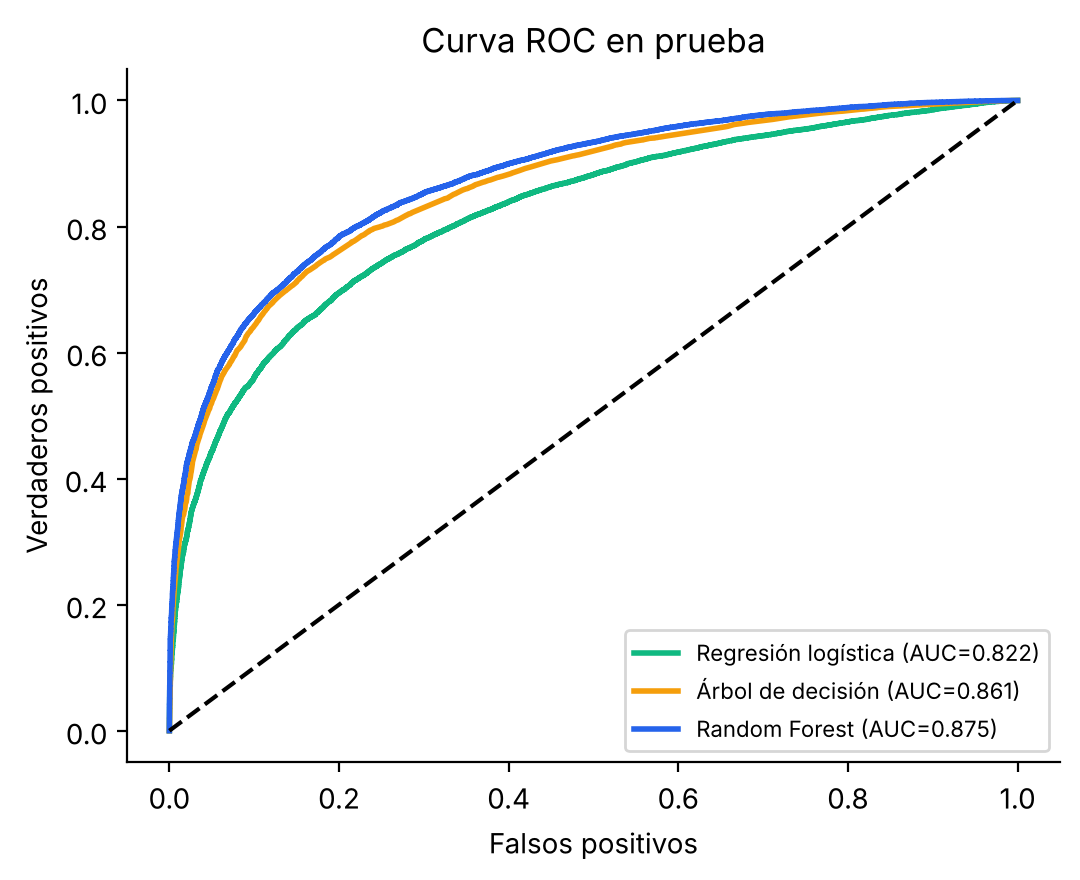

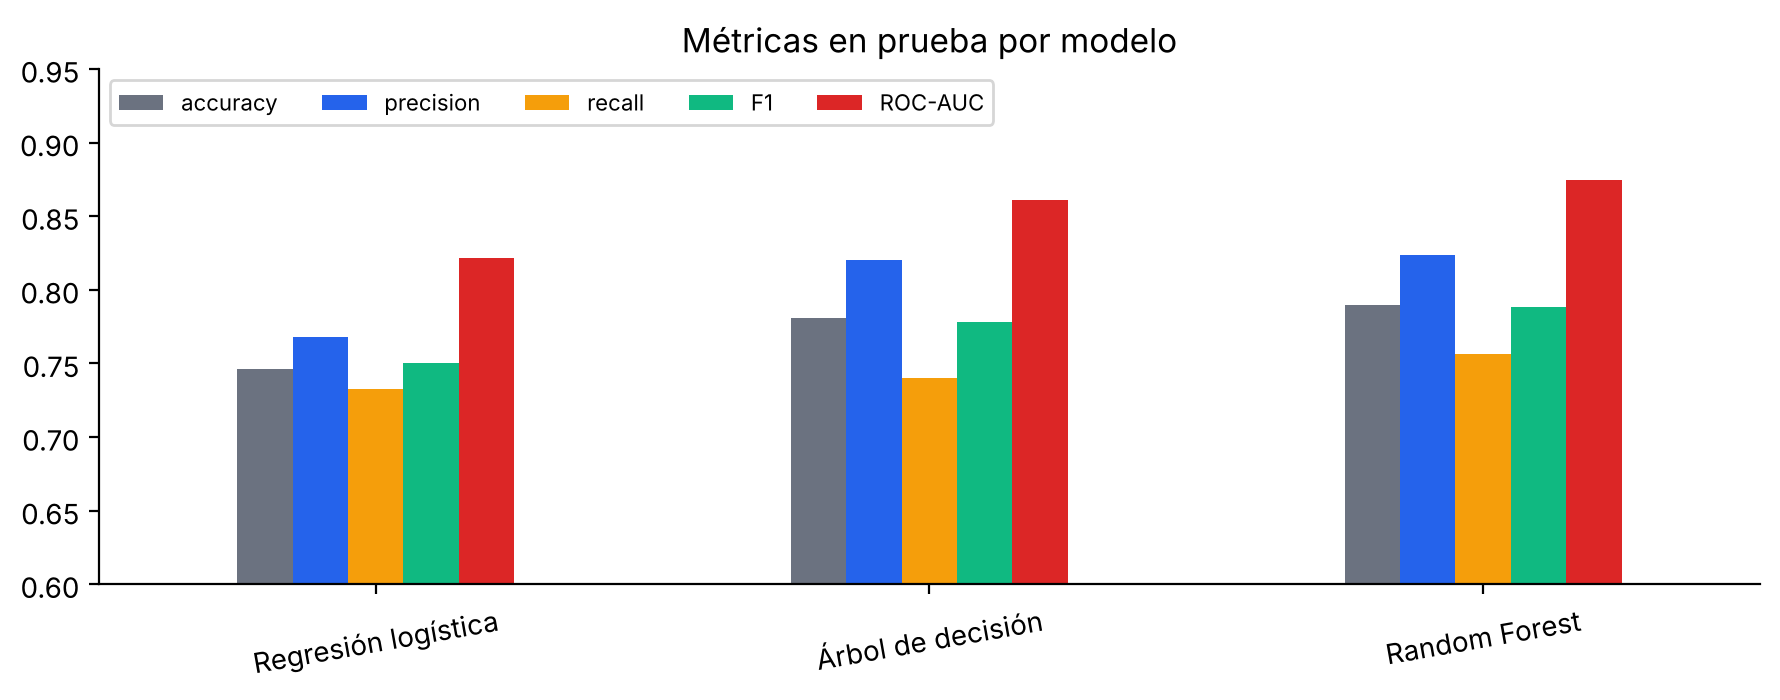

In [15]:
nombres = list(mejores.keys())
mejor_nombre = nombres[0]
for n in nombres:
    if resultados[n]["AUC validación"] > resultados[mejor_nombre]["AUC validación"]:
        mejor_nombre = n
R["mejor_modelo"] = mejor_nombre
print("Mejor modelo:", mejor_nombre)

colores = {"Regresión logística": VERDE, "Árbol de decisión": NARANJA, "Random Forest": AZUL}

# Curva ROC
plt.figure(figsize=(5.5, 4.5))
for n in nombres:
    fpr, tpr, _ = roc_curve(y_test, probabilidades[n])
    plt.plot(fpr, tpr, color=colores[n], linewidth=2, label=n + " (AUC=" + str(round(resultados[n]["ROC-AUC"], 3)) + ")")
plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("Falsos positivos")
plt.ylabel("Verdaderos positivos")
plt.title("Curva ROC en prueba")
plt.legend(loc="lower right", fontsize=8)
guardar("f12_roc")

# Comparacion de metricas
met = pd.DataFrame(resultados).T.loc[nombres, ["accuracy", "precision", "recall", "F1", "ROC-AUC"]]
met.plot.bar(figsize=(9, 3.6), rot=10, color=[GRIS, AZUL, NARANJA, VERDE, ROJO])
plt.ylim(0.6, 0.95)
plt.title("Métricas en prueba por modelo")
plt.legend(ncol=5, fontsize=8, loc="upper left")
guardar("f13_metricas")

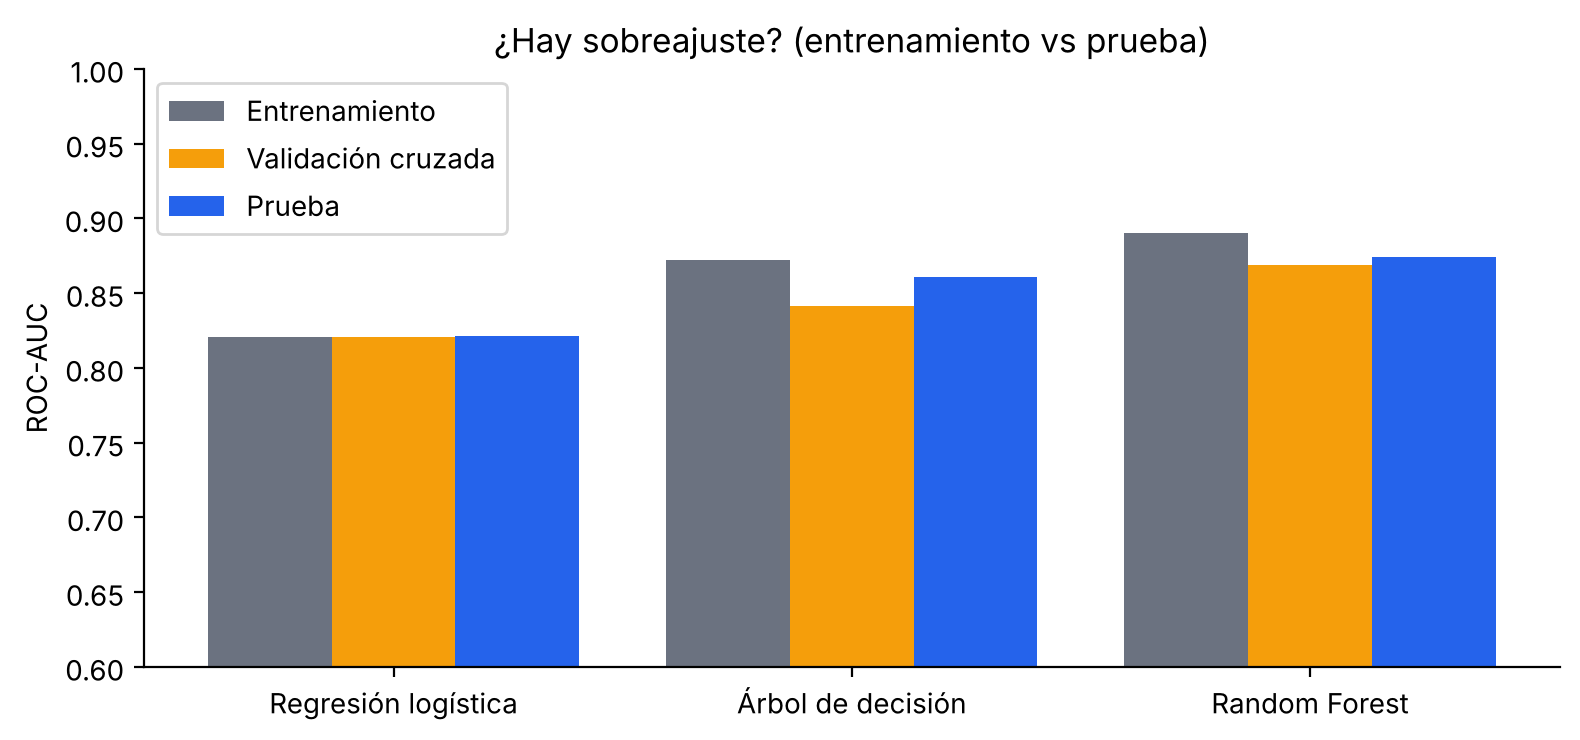

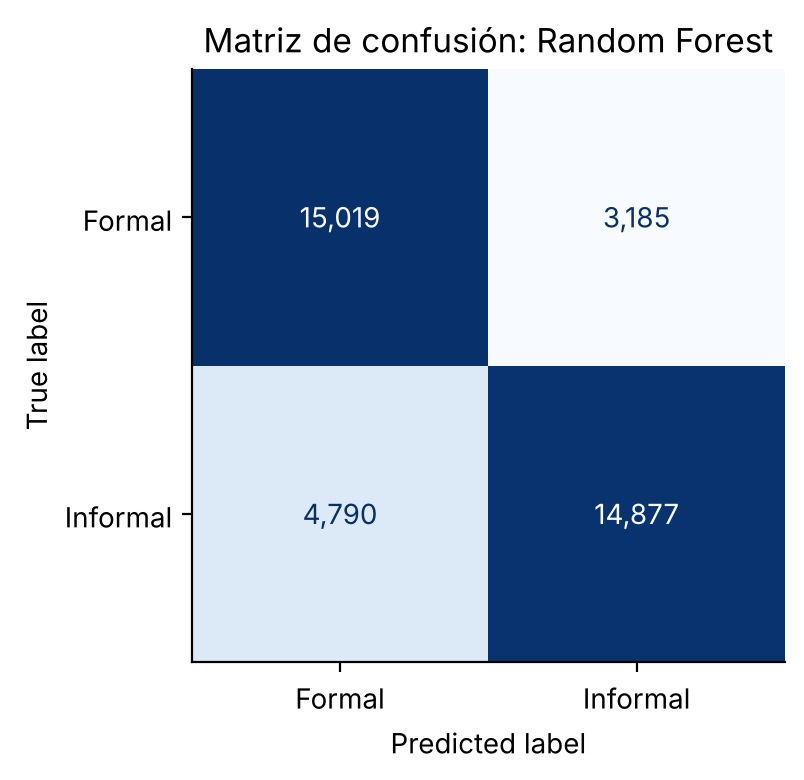

In [16]:
# Sobreajuste: comparo AUC de entrenamiento, validacion y prueba
x = np.arange(len(nombres))
plt.figure(figsize=(8, 3.8))
plt.bar(x - 0.27, [resultados[n]["AUC entrenamiento"] for n in nombres], 0.27, label="Entrenamiento", color=GRIS)
plt.bar(x, [resultados[n]["AUC validación"] for n in nombres], 0.27, label="Validación cruzada", color=NARANJA)
plt.bar(x + 0.27, [resultados[n]["ROC-AUC"] for n in nombres], 0.27, label="Prueba", color=AZUL)
plt.xticks(x, nombres)
plt.ylim(0.6, 1.0)
plt.ylabel("ROC-AUC")
plt.title("¿Hay sobreajuste? (entrenamiento vs prueba)")
plt.legend()
guardar("f14_sobreajuste")

# Matriz de confusion del mejor modelo
pred_mejor = (probabilidades[mejor_nombre] >= 0.5).astype(int)
cm = confusion_matrix(y_test, pred_mejor)
R["confusion"] = cm.tolist()
fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay(cm, display_labels=["Formal", "Informal"]).plot(ax=ax, cmap="Blues", colorbar=False, values_format=",d")
ax.set_title("Matriz de confusión: " + mejor_nombre)
guardar("f15_confusion")

## 5. Estructura, funcionamiento y eficiencia del programa

**Lenguaje y herramientas:** Python en Google Colab, con pandas, numpy, matplotlib, seaborn, scipy y scikit-learn (explicadas al inicio).

**Etapas del programa:**
1. Descargar y leer los datos.
2. Filtrar la población de estudio.
3. Limpiar (códigos, nulos, duplicados, atípicos).
4. Convertir variables cualitativas (`get_dummies`) y dividir en entrenamiento/prueba.
5. Estandarizar y rellenar nulos con datos de entrenamiento.
6. Buscar parámetros (`GridSearchCV`) y entrenar los modelos.
7. Evaluar con las métricas e interpretar.

**Instrucciones más importantes:**
- `train_test_split(..., stratify=y)`: divide los datos conservando la proporción de clases.
- `pd.get_dummies(...)`: convierte categorías en columnas de 0 y 1.
- `StandardScaler().fit_transform(...)`: estandariza (se "aprende" con train y se aplica a test con `transform`).
- `GridSearchCV(..., cv=5)`: prueba todas las combinaciones de parámetros con validación cruzada.
- `modelo.fit(X, y)` y `modelo.predict_proba(X)`: entrenar y predecir probabilidades.

### 5.1 Tiempos de cada modelo (operaciones más pesadas)

,Búsqueda de parámetros (s),Entrenamiento final (s),Predicción por 10 mil filas (s)
Regresión logística,15.47,1.75,0.00
Árbol de decisión,4.12,0.72,0.00
Random Forest,25.78,4.49,0.06


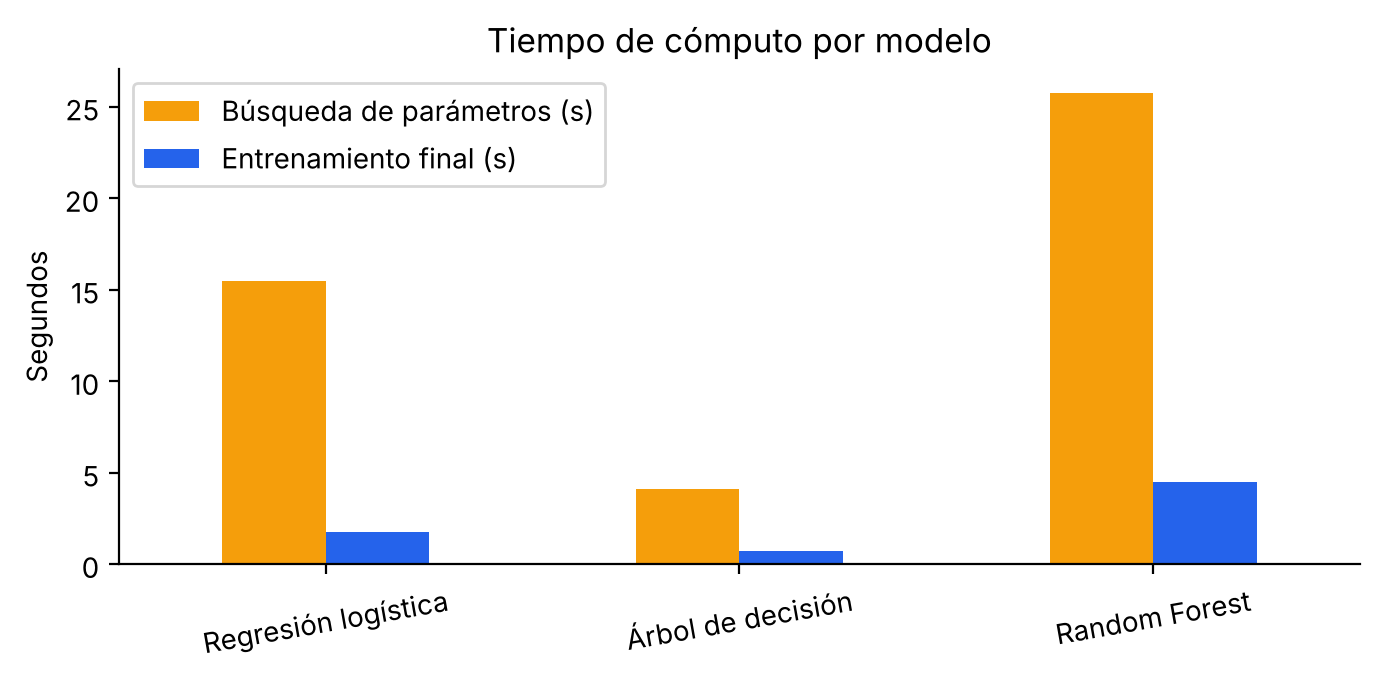

In [17]:
tiempos = pd.DataFrame(resultados).T.loc[nombres, ["t_busqueda", "t_entrenar", "t_predecir"]].astype(float)
tiempos.columns = ["Búsqueda de parámetros (s)", "Entrenamiento final (s)", "Predicción por 10 mil filas (s)"]
R["tiempos"] = tiempos.round(3).to_dict("index")
display(tiempos.round(2))

tiempos.iloc[:, :2].plot.bar(figsize=(7, 3.5), rot=10, color=[NARANJA, AZUL])
plt.ylabel("Segundos")
plt.title("Tiempo de cómputo por modelo")
guardar("f16_tiempos")

### 5.2 Complejidad temporal
Uso *n* = número de filas, *p* = número de variables y *T* = número de árboles.

| Modelo | Entrenamiento | Predecir una fila |
|---|---|---|
| Regresión logística | O(n · p · iteraciones) | O(p) |
| Árbol de decisión | O(n · p · log n) | O(profundidad) |
| Random Forest | O(T · n · p · log n) | O(T · profundidad) |

Para comprobar esto midí cuánto tarda cada modelo al aumentar el número de filas.

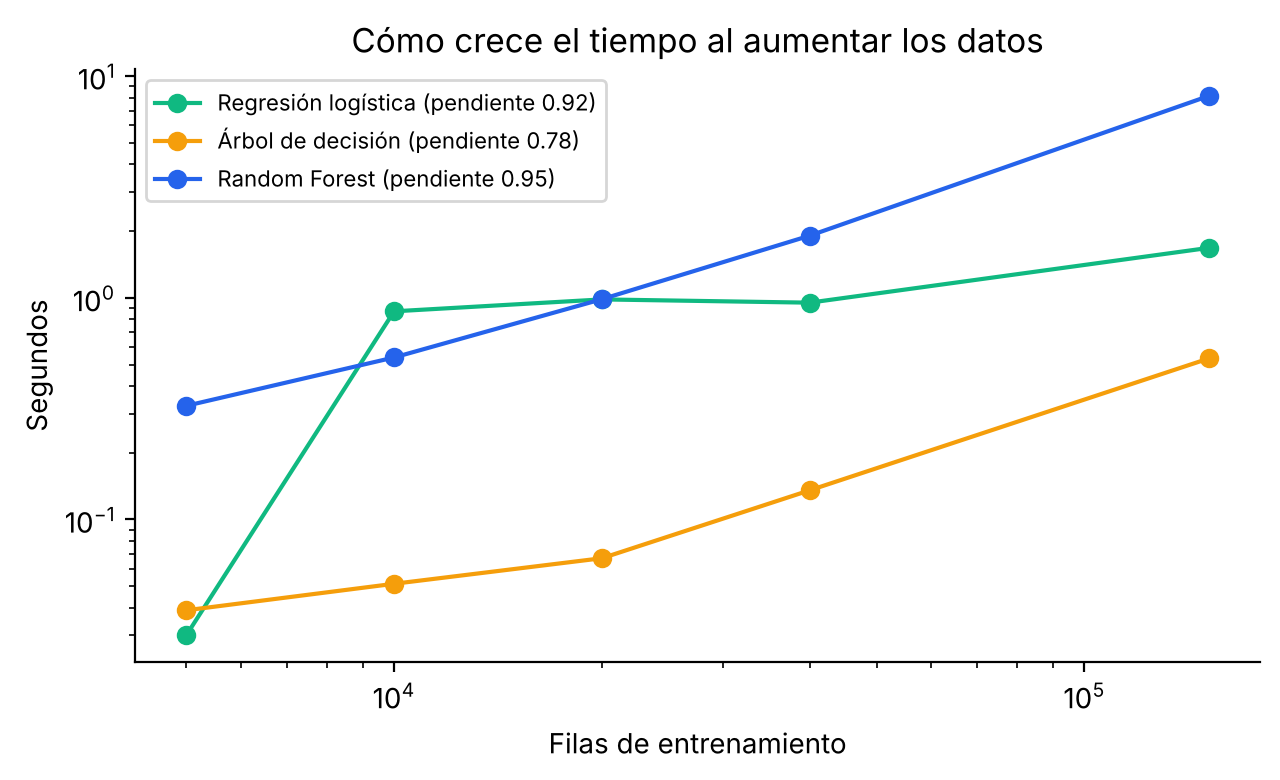

{'Regresión logística': 0.92, 'Árbol de decisión': 0.78, 'Random Forest': 0.95}


In [18]:
tamanios = [5000, 10000, 20000, 40000, len(X_train)]
modelos_escala = {"Regresión logística": LogisticRegression(max_iter=1000),
                  "Árbol de decisión": DecisionTreeClassifier(max_depth=8, random_state=SEMILLA),
                  "Random Forest": RandomForestClassifier(n_estimators=100, max_depth=12, random_state=SEMILLA, n_jobs=1)}
escala = {}
for nombre in modelos_escala:
    lista = []
    for n in tamanios:
        indices = X_train.sample(n, random_state=SEMILLA).index
        base_X = X_train_esc if nombre == "Regresión logística" else X_train
        t0 = time.time()
        modelos_escala[nombre].fit(base_X.loc[indices], y_train.loc[indices])
        lista.append(time.time() - t0)
    escala[nombre] = lista

# Pendiente en escala log-log (1 = crece parecido a n)
pendientes = {}
for nombre in escala:
    pendientes[nombre] = float(np.polyfit(np.log(tamanios), np.log(escala[nombre]), 1)[0])
R["escalamiento"] = {"n": tamanios, "tiempos": escala, "pendientes": pendientes}

plt.figure(figsize=(6.5, 4))
for nombre in escala:
    plt.plot(tamanios, escala[nombre], "o-", color=colores[nombre], label=nombre + " (pendiente " + str(round(pendientes[nombre], 2)) + ")")
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Filas de entrenamiento")
plt.ylabel("Segundos")
plt.title("Cómo crece el tiempo al aumentar los datos")
plt.legend(fontsize=8)
guardar("f17_escalamiento")
print({k: round(v, 2) for k, v in pendientes.items()})

### 5.3 ¿Se pueden reproducir los resultados? Y mejoras
Fijé `random_state=42` en todo. Para comprobarlo, entreno el mejor modelo dos veces y comparo.

**Mejoras posibles:** guardar el modelo con `joblib` para no volver a entrenar; poner el código en funciones para reutilizarlo; probar menos combinaciones (`RandomizedSearchCV`) para que sea más rápido; usar solo las columnas necesarias al leer el CSV para gastar menos memoria; poner comentarios y nombres más claros.

In [19]:
if mejor_nombre == "Regresión logística":
    Xr_tr, Xr_te = X_train_esc, X_test_esc
else:
    Xr_tr, Xr_te = X_train, X_test
m1 = mejores[mejor_nombre].fit(Xr_tr, y_train)
p1 = m1.predict_proba(Xr_te)[:, 1]
m2 = mejores[mejor_nombre].fit(Xr_tr, y_train)
p2 = m2.predict_proba(Xr_te)[:, 1]
R["reproducible"] = bool(np.allclose(p1, p2))
print("¿Salen las mismas predicciones al repetir?", R["reproducible"])

¿Salen las mismas predicciones al repetir? True


## 6. Resultados, interpretación y conclusiones

### 6.1 ¿Qué variables importan más?
Uso la **importancia de variables del Random Forest** (qué tanto ayuda cada variable a separar formales e informales). Como `get_dummies` partió las categorías en varias columnas, las sumo de nuevo por variable original.

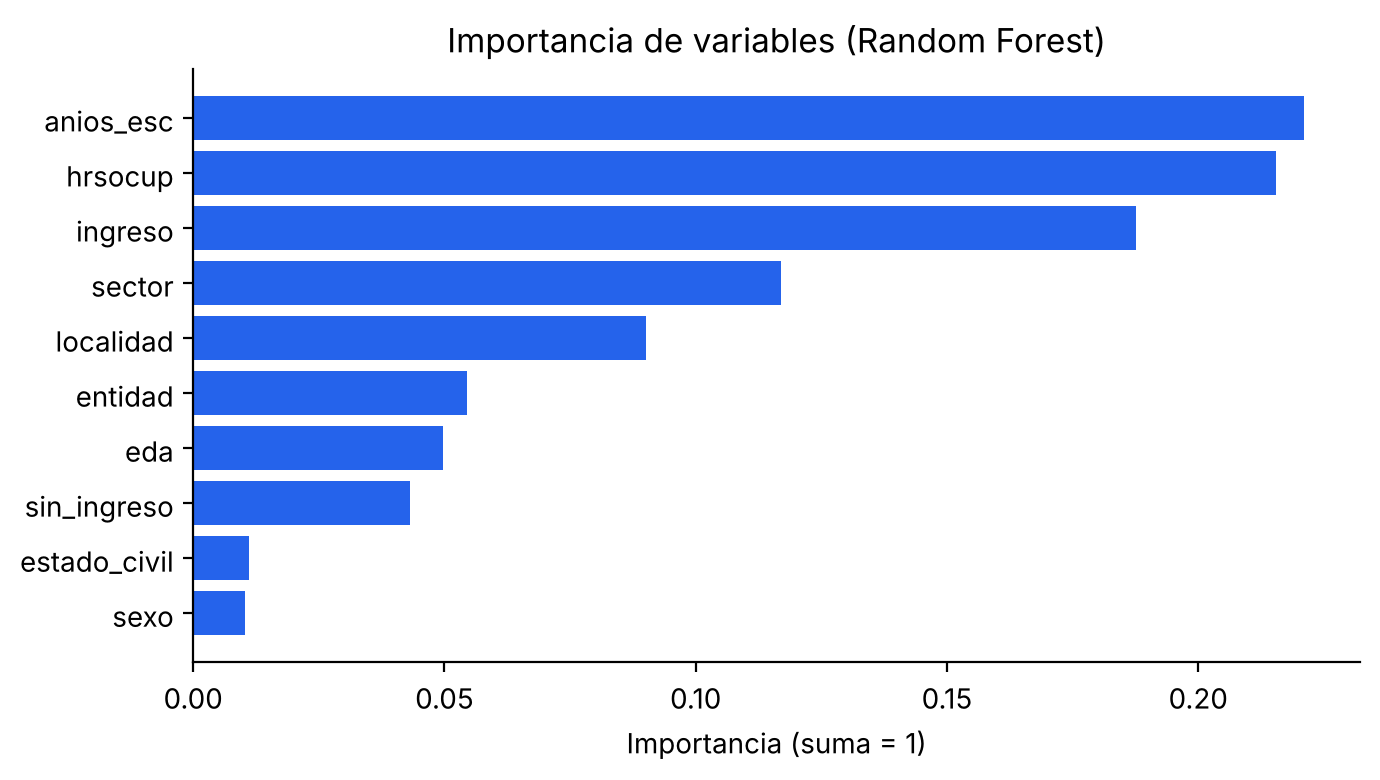

anios_esc       0.221
hrsocup         0.216
ingreso         0.188
sector          0.117
localidad       0.090
entidad         0.054
eda             0.050
sin_ingreso     0.043
estado_civil    0.011
sexo            0.010


In [20]:
rf = mejores["Random Forest"]
importancias = pd.Series(rf.feature_importances_, index=X_train.columns)
resumen_imp = {}
for var in numericas + ["sin_ingreso"] + categoricas:
    total = 0
    for col in X_train.columns:
        if col == var or col.startswith(var + "_"):
            total = total + importancias[col]
    resumen_imp[var] = total
resumen_imp = pd.Series(resumen_imp).sort_values()
R["importancia"] = resumen_imp.round(4).to_dict()

plt.figure(figsize=(7, 4))
plt.barh(resumen_imp.index, resumen_imp.values, color=AZUL)
plt.xlabel("Importancia (suma = 1)")
plt.title("Importancia de variables (Random Forest)")
guardar("f18_importancia")
print(resumen_imp.sort_values(ascending=False).round(3).to_string())

### 6.2 Razones de momios (odds ratio) y contraste de hipótesis
Con la regresión logística, `exp(coeficiente)` es la **razón de momios (OR)**: si OR > 1 la variable *aumenta* la probabilidad de informalidad; si OR < 1 la *disminuye*. Las numéricas están estandarizadas, así que su OR es "por cada aumento de 1 desviación estándar". Las categorías se comparan contra la categoría que se quitó con `drop_first` (la primera en orden alfabético: hombre, casado, localidad de 15 mil a 100 mil, sector agropecuario y Aguascalientes).

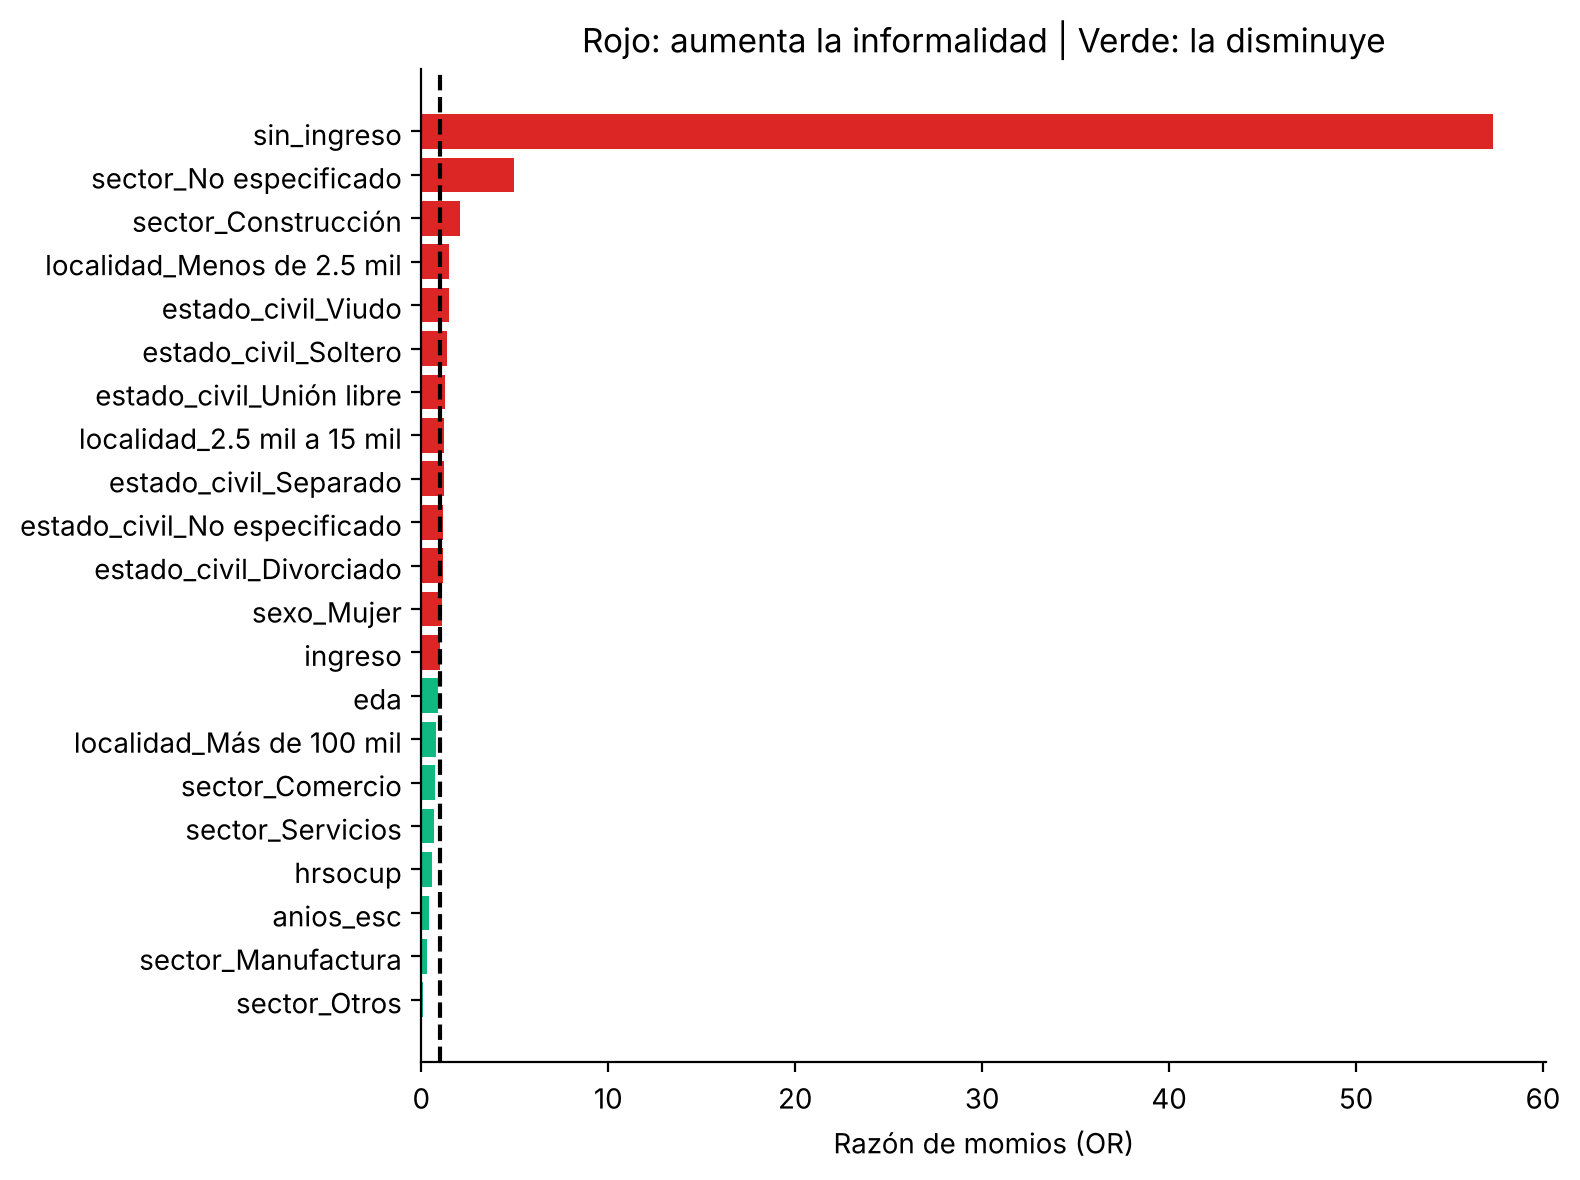

,coeficiente,OR
sector_Otros,-2.246,0.106
sector_Manufactura,-1.229,0.293
anios_esc,-0.922,0.398
hrsocup,-0.577,0.561
sector_Servicios,-0.374,0.688
sector_Comercio,-0.318,0.727
localidad_Más de 100 mil,-0.252,0.777
eda,-0.133,0.875
ingreso,0.020,1.020
sexo_Mujer,0.110,1.117


In [21]:
rl = mejores["Regresión logística"]
coef = pd.Series(rl.coef_[0], index=X_train_esc.columns)
OR = np.exp(coef)
tabla_or = pd.DataFrame({"coeficiente": coef, "OR": OR})
R["or"] = tabla_or.round(4).to_dict("index")

# Grafica de las variables que no son entidad
sin_estado = tabla_or[[not c.startswith("entidad_") for c in tabla_or.index]].sort_values("OR")
plt.figure(figsize=(8, 6))
plt.barh(sin_estado.index, sin_estado["OR"], color=[ROJO if v > 1 else VERDE for v in sin_estado["OR"]])
plt.axvline(1, color="black", linestyle="--")
plt.xlabel("Razón de momios (OR)")
plt.title("Rojo: aumenta la informalidad | Verde: la disminuye")
guardar("f19_odds_ratios")
display(sin_estado.round(3))

In [22]:
# ----- Contraste de hipotesis -----
hipotesis = []

# H1: escolaridad (correlacion de Spearman + OR)
sub = d[["anios_esc", "y"]].dropna()
rho, p1 = stats.spearmanr(sub["anios_esc"], sub["y"])
or1 = OR["anios_esc"]
hipotesis.append({"Hipótesis": "H1 escolaridad", "Prueba": "Spearman", "Estadístico": rho, "p-value": p1, "OR": or1,
                  "Veredicto": "RESPALDADA" if (rho < 0 and or1 < 1 and p1 < 0.05) else "RECHAZADA"})

# H2: localidad pequeña (chi cuadrada entre <2.5 mil y >100 mil + OR)
sub2 = d[d["localidad"].isin(["Menos de 2.5 mil", "Más de 100 mil"])]
tabla2 = pd.crosstab(sub2["localidad"], sub2["y"])
chi2, p2, gl, esp = stats.chi2_contingency(tabla2)
# Con drop_first la categoria quitada es "15 mil a 100 mil"; para comparar contra ">100 mil" divido los dos OR
or2 = OR["localidad_Menos de 2.5 mil"] / OR["localidad_Más de 100 mil"]
tasa_rural = d[d["localidad"] == "Menos de 2.5 mil"]["y"].mean() * 100
tasa_urbana = d[d["localidad"] == "Más de 100 mil"]["y"].mean() * 100
hipotesis.append({"Hipótesis": "H2 localidad pequeña", "Prueba": "Chi cuadrada", "Estadístico": chi2, "p-value": p2, "OR": or2,
                  "Veredicto": "RESPALDADA" if (tasa_rural > tasa_urbana and or2 > 1 and p2 < 0.05) else "RECHAZADA"})

# H3: ingreso (t de Student + OR)
inf = d[d["y"] == 1]["ingreso"].dropna()
form = d[d["y"] == 0]["ingreso"].dropna()
t3, p3 = stats.ttest_ind(inf, form, equal_var=False)
or3 = OR["ingreso"]
hipotesis.append({"Hipótesis": "H3 ingreso", "Prueba": "t de Student", "Estadístico": t3, "p-value": p3, "OR": or3,
                  "Veredicto": "RESPALDADA" if (inf.mean() < form.mean() and or3 < 1 and p3 < 0.05) else "RECHAZADA"})

hipotesis = pd.DataFrame(hipotesis)
R["hipotesis"] = hipotesis.to_dict("records")
R["tasa_rural"], R["tasa_urbana"] = float(tasa_rural), float(tasa_urbana)
R["ingreso_medio"] = {"informal": float(inf.mean()), "formal": float(form.mean())}
display(hipotesis.round(4))
print("% informal en localidades <2.5 mil:", round(tasa_rural, 1), "| en >100 mil:", round(tasa_urbana, 1))
print("Ingreso mensual medio -> informal: $", round(inf.mean()), "| formal: $", round(form.mean()))

,Hipótesis,Prueba,Estadístico,p-value,OR,Veredicto
0,H1 escolaridad,Spearman,-0.3741,0.0,0.3976,RESPALDADA
1,H2 localidad pequeña,Chi cuadrada,10090.0306,0.0,1.9063,RESPALDADA
2,H3 ingreso,t de Student,-96.2641,0.0,1.0199,RECHAZADA


% informal en localidades <2.5 mil: 75.1 | en >100 mil: 42.1
Ingreso mensual medio -> informal: $ 6237 | formal: $ 10529


In [23]:
# Resumen final y guardado de resultados
mj = resultados[mejor_nombre]
R["resumen"] = {"mejor": mejor_nombre, "auc_test": mj["ROC-AUC"], "auc_val": mj["AUC validación"], "f1": mj["F1"],
                "accuracy": mj["accuracy"], "precision": mj["precision"], "recall": mj["recall"],
                "diferencia": mj["AUC entrenamiento"] - mj["ROC-AUC"]}
tabla.round(5).to_csv("resultados/metricas_modelos.csv")

def a_json(o):
    if isinstance(o, np.integer): return int(o)
    if isinstance(o, np.floating): return float(o)
    if isinstance(o, np.ndarray): return o.tolist()
    return str(o)
json.dump(R, open("resultados/resumen.json", "w"), ensure_ascii=False, indent=1, default=a_json)

print("Mejor modelo:", mejor_nombre)
print("ROC-AUC prueba:", round(mj["ROC-AUC"], 3), "| F1:", round(mj["F1"], 3), "| accuracy:", round(mj["accuracy"], 3))
print("Diferencia entrenamiento - prueba (AUC):", round(R["resumen"]["diferencia"], 3))

Mejor modelo: Random Forest
ROC-AUC prueba: 0.875 | F1: 0.789 | accuracy: 0.789
Diferencia entrenamiento - prueba (AUC): 0.016


### 6.3 Limitaciones y trabajo futuro
**Limitaciones.** (1) Usé un solo trimestre de la ENOE. (2) No usé el factor de expansión en los modelos, así que los resultados describen la muestra y no a toda la población. (3) El modelo muestra relaciones, **no causas**. (4) Dejé fuera a propósito las variables que definen la informalidad.

**Trabajo futuro.** Usar varios trimestres, ponderar con el factor de expansión, probar otros modelos (por ejemplo gradient boosting) y agregar más variables.

Las conclusiones completas con las cifras están en el documento del proyecto.